# Direct vs app-store channels: AI subscription gross adds and churn on e-receipts

For each AI provider, this notebook builds monthly gross adds and churn from three receipt channels in `srs_slice.common.items_v` (NIQ / Slice, US) and compares them:

1. **Direct:** the provider's own sender, e.g. `Chat GPT` / `Chat GPT Cancellation`.
2. **Google Play:** `Google Play` / `Google Play Cancellation`.
3. **App Store:** `iTunes` / `iTunes Cancellation`.

Each comparison chart also shows the **modelled** gross adds and churn from the `ai_consumer` job (`srs_mcp.ai_consumer.subs_monthly`, US, all plans). These are from yesterday's method:
- **Modelled gross adds:** the first paid receipt of a subscription, pooled across every channel the model reads.
- **Modelled churn:** churn rates from the reliable subset, applied to modelled subscribers. Churn is dated when a subscription lapses (last payment plus the lapse window), not when a cancellation email arrives. The two measures cover different mailboxes, so a consistent one-month lag isn't visible in the charts.

Each chart also shows a **combined, deduped** line (purple, thicker): gross adds and churn across direct, Google Play and iTunes. Each channel is first built with its own rules (below). An add or cancellation for a mailbox within 45 days of an add or cancellation for the same mailbox in a different channel counts once, at the first date (for example, a Google One welcome email plus a Google Play receipt for the same Gemini sign-up). Mailboxes are distinct per month.

The modelled and combined numbers are one total per provider, not extra channels, so they are left out of the channel shares. The table under each chart gives the combined total as a share of the summed channels; one minus that share is the cross-channel overlap. See the per-provider notes for which channels the model covers.

**Common rules (all sections)**
- **Unit:** distinct `mailbox_id` per `order_date` month. All mailboxes are included, with no panel-status filter. Counts are at provider level: any tier counts, and a tier switch is not a new add.
- **Gross add:** the first sign-up or paid subscription email in a consecutive series for a mailbox in that channel. A new series starts when the previous sign-up/paid email is more than **75 days** earlier, or **400 days** if that email was for an annual plan, or when a cancellation email arrived in between. The 75-day window comes from renewal gaps: store renewals are a median 31 days apart, and 4–12% of gaps are 36–75 days (one missed email). How each channel's emails map to "sign-up" and "paid" is set per channel below, after looking at the structure.
- **Churn:** cancellation emails only. Several emails about the same cancellation (e.g. Google Play's "will be canceled on…" followed by "…will end on…") count once: emails for one mailbox within 45 days, with no sign-up/paid email between them, are one cancellation, dated at the first.
- Paid rows exclude credits, tokens and other one-off purchases. Free-trial notices are not adds; a trial that converts shows up as an add at its first paid receipt.
- Data runs to the latest `order_date` loaded. **The last month is partial.** Charts stop at the last complete month.

The filter and engine code is in `channel_rules.py`. The raw candidate rows are cached in `../.cache/channel_cmp/raw.parquet`. Delete that file to re-pull it (about 5 minutes on `ANALYST_L`).

In [1]:
import re, sys, warnings, pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
warnings.filterwarnings("ignore", message="This pattern is interpreted")
warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path
from IPython.display import display, Markdown
import channel_rules as R
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 110); pd.set_option("display.max_rows", 200)

CACHE = Path("../.cache/channel_cmp/raw.parquet")
RX = "chat ?gpt|open ?ai|claude|anthropic|gemini|google one|google ai|grok|perplexity|muse from meta|power plan|maximum plan"
SQL = f'''
SELECT mailbox_id, merchant_id, merchant_name, order_date, email_sent_time, order_id, item_id, description, item_price, order_total
FROM srs_slice.common.items_v
WHERE order_date >= '2024-07-01' AND (
      merchant_id IN (4070, 4078, 20127, 20139, 4212, 4213, 20187, 20191)          -- direct senders
   OR (merchant_id = 3848 AND description ILIKE '%muse%')                            -- Meta (Muse)
   OR (merchant_id IN (5, 20122, 1493, 3452) AND REGEXP_LIKE(description, '.*({RX}).*', 'is')))  -- iTunes / Google Play
'''
if not CACHE.exists():
    import snowflake.connector as sc
    cur = sc.connect(connection_name="default", warehouse="ANALYST_L", network_timeout=3600).cursor()
    cur.execute(SQL); raw = cur.fetch_pandas_all(); raw.columns = [c.lower() for c in raw.columns]
    CACHE.parent.mkdir(parents=True, exist_ok=True); raw.to_parquet(CACHE, index=False)
df = pd.read_parquet(CACHE)
df["d"] = df.description.str.lower().fillna("")
df["dt"] = pd.to_datetime(df.order_date)
df["channel"] = np.select([df.merchant_id.isin([1493, 3452]), df.merchant_id.isin([5, 20122])], ["gp", "itunes"], "direct")
df["cancel_sender"] = df.merchant_id.isin([4078, 20139, 4213, 20191, 3452, 20122])
df["priced"] = df.item_price.fillna(0) > 0
DATA_END = df.dt.max()
LAST_FULL = DATA_END.to_period("M") if DATA_END.is_month_end else pd.Period(DATA_END - pd.offsets.MonthEnd(1), "M")
print(f"{len(df):,} candidate rows; data end {DATA_END.date()}; charts end {LAST_FULL}")

# Modelled gross adds and churn from the ai_consumer job (yesterday's method). Re-read on every run; a copy is cached for offline use.
MODEL_CACHE = Path("../.cache/channel_cmp/model_subs_monthly.parquet")
try:
    import snowflake.connector as sc
    cur = sc.connect(connection_name="default", warehouse="ANALYST_L").cursor()
    cur.execute("SELECT provider, plan, month, gross_adds, churn, held, loaded_at FROM srs_mcp.ai_consumer.subs_monthly "
                "WHERE region = 'us' AND country = 'us' AND month >= '2025-01-01'")
    model_raw = cur.fetch_pandas_all(); model_raw.columns = [c.lower() for c in model_raw.columns]; model_raw.to_parquet(MODEL_CACHE, index=False)
except Exception as e:
    print("Snowflake unavailable, using cached modelled table:", e); model_raw = pd.read_parquet(MODEL_CACHE)
print("modelled table loaded at", model_raw.loaded_at.max())
df.groupby(["merchant_id", "merchant_name"]).size().rename("rows_since_2024_07").to_frame()

12,249,110 candidate rows; data end 2026-10-20; charts end 2026-09


modelled table loaded at 2026-10-20 08:53:39.369000


,,rows_since_2024_07
merchant_id,merchant_name,
5,iTunes,1474643
1493,Google Play,7416861
3452,Google Play Cancellation,335209
3848,Meta,1264
4070,Chat GPT,303638
4078,Chat GPT Cancellation,180521
4212,Perplexity AI,140373
4213,Perplexity AI Cancellation,28729
20122,iTunes Cancellation,168818


In [2]:
COLORS = {"Direct": "#2a78d6", "Google Play": "#eb6834", "iTunes": "#1baf7a", "Modelled": "#3d3d3a", "Combined": "#8b5cc8"}
EVENTS = {}  # id(monthly table) -> (add events, churn events), each mailbox_id + dt; used to build the deduped combined line
DEDUP_DAYS = 45

def combined(tabs):
    '''Gross adds and churn across channels, deduped: an add (or cancellation) for a mailbox within DEDUP_DAYS after an add
    (or cancellation) for the same mailbox in a different channel is the same event and is counted once, at the first date.'''
    out = []
    for k in (0, 1):
        ev = pd.concat([EVENTS[id(t)][k].assign(ch=lab) for lab, t in tabs.items()]).sort_values(["mailbox_id", "dt"]).reset_index(drop=True)
        same = ev.mailbox_id.eq(ev.mailbox_id.shift())
        dup = same & ev.ch.ne(ev.ch.shift()) & ((ev.dt - ev.dt.shift()).dt.days <= DEDUP_DAYS)
        out.append(ev[~dup])
    return R.monthly(out[0], out[1])

def model_tab(provider, exclude_plans=None):
    '''Modelled monthly gross adds and churn for one provider: the sum over plans, optionally excluding some plans (regex).'''
    m = model_raw[(model_raw.provider == provider) & (model_raw.plan != "all")]
    if exclude_plans: m = m[~m.plan.str.contains(exclude_plans)]
    t = m.assign(month=pd.to_datetime(m.month).dt.to_period("M")).groupby("month")[["gross_adds", "churn"]].sum().round().astype(int)
    held = model_raw[model_raw.held].month.pipe(pd.to_datetime).dt.to_period("M").unique()
    return t[~t.index.isin(held)]

def has(rx):
    return df.d.str.contains(rx, regex=True)

def sequences(mask, n=4, seed=0, since="2025-06-01"):
    '''Print the full email sequence (ordered by mailbox_id, order_date) for n mailboxes that have a cancellation since `since`.'''
    rows = df[mask].sort_values(["mailbox_id", "dt", "email_sent_time"])
    pick = rows[rows.cancel_sender & (rows.dt >= since)].mailbox_id.drop_duplicates()
    pick = pick.sample(min(n, len(pick)), random_state=seed) if len(pick) else rows.mailbox_id.drop_duplicates().sample(min(n, rows.mailbox_id.nunique()), random_state=seed)
    out = rows[rows.mailbox_id.isin(pick)][["mailbox_id", "order_date", "merchant_name", "description", "item_price"]]
    display(out.head(60))

def patterns(mask, top=15):
    '''Most common description patterns (digits replaced by #) since 2025, split by sender, with priced share.'''
    x = df[mask & (df.dt >= "2025-01-01")]
    p = x.assign(pattern=x.d.str.replace(r"\d+", "#", regex=True).str.slice(0, 110))
    t = p.groupby(["merchant_name", "pattern"]).agg(rows=("item_id", "size"), priced_share=("priced", "mean"), median_price=("item_price", "median"))
    display(t.sort_values("rows", ascending=False).groupby(level=0, group_keys=False).head(top).round(2))

# Google Play paid receipt: priced and "auto-renewing subscription". Free-trial notices quote the same plan text but are unpriced.
GP_PAY = (df.merchant_id == 1493) & df.priced & df.d.str.contains("auto-renewing subscription") & ~df.d.str.startswith("your trial")

def build(mask_rows, signup, pay, cancel, annual=None, parts=False):
    rows = df[mask_rows]
    f = lambda m: (m if isinstance(m, pd.Series) else pd.Series(m, index=df.index))[mask_rows] if m is not None else pd.Series(False, index=rows.index)
    tab, adds, churn, sig_rows = R.run(rows, f(signup), f(pay), f(cancel), f(annual) if annual is not None else None)
    # churn with no sign-up/paid email for the mailbox in this channel in the prior 400 days (e.g. trials cancelled before paying)
    sig = rows[f(signup) | f(pay)][["mailbox_id", "dt"]].rename(columns={"dt": "sdt"}).sort_values("sdt")
    j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))
    tab.attrs["churn_no_prior_add"] = j[j.dt >= "2025-01-01"].sdt.isna().mean() if len(j) else np.nan
    EVENTS[id(tab)] = (adds[["mailbox_id", "dt", "row"]], churn[["mailbox_id", "dt", "row"]], sig_rows[["mailbox_id", "dt", "row"]])
    return (tab, adds, churn) if parts else tab

def show(tab, title):
    display(Markdown(f"**{title}** (month {DATA_END.to_period('M')} is partial)"))
    display(tab.T)

def compare(tabs, title, extra_styles=None, model=None, model_covers=None):
    '''tabs: {channel label: monthly table}. Three panels (gross adds, churn, implied net adds = gross adds - churn), one line per channel plus the modelled total, from 2025-01.'''
    chans = {lab: t for lab, t in tabs.items() if lab in ("Direct", "Google Play", "iTunes")}
    comb = combined(chans)
    lines = dict(tabs, Combined=comb, **({"Modelled": model} if model is not None else {}))
    extra_styles = dict({"Combined": {"lw": 2.8}}, **(extra_styles or {}))
    fig, axes = plt.subplots(1, 3, figsize=(21, 4.6), sharex=True)
    for ax, col, name in zip(axes, ["gross_adds", "churn", "net_adds"], ["Gross adds", "Churn (channels: cancellation emails; modelled: lapses)", "Implied net adds (gross adds − churn)"]):
        for lab, t in lines.items():
            t = t[t.index <= LAST_FULL]
            # net adds only where the line has both adds and churn, otherwise it would just repeat one of them
            if col == "net_adds" and (t.gross_adds.sum() == 0 or t.churn.sum() == 0): continue
            s = t.gross_adds - t.churn if col == "net_adds" else t[col]
            if s.sum() == 0 and col != "net_adds": continue
            sty = (extra_styles or {}).get(lab, {})
            ax.plot(s.index.to_timestamp(), s.values, lw=sty.get("lw", 2), label=lab if lab != "Combined" else f"Combined, deduped ({' + '.join(chans)})", color=sty.get("color", COLORS.get(lab)), ls=sty.get("ls", "-"))
        ax.set_title(name, loc="left", fontsize=11); ax.grid(axis="y", color="#e5e5e5", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
        if col == "net_adds": ax.axhline(0, color="#999999", lw=0.8)
        else: ax.set_ylim(bottom=0)
        ax.set_ylabel("mailboxes per month")
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    axes[0].legend(frameon=False, loc="upper left")
    fig.suptitle(title, x=0.01, ha="left", fontsize=13); fig.tight_layout(); plt.show()
    # channel share of the total over complete months since 2025-01
    tot = pd.DataFrame({lab: t[t.index <= LAST_FULL][["gross_adds", "churn"]].sum() for lab, t in tabs.items()}).T
    share = (tot / tot.sum()).round(3).add_suffix("_share")
    # correlation of each channel's monthly series with the others
    out = pd.concat([tot, share], axis=1)
    ct = comb[(comb.index >= "2025-01") & (comb.index <= LAST_FULL)][["gross_adds", "churn"]].sum()
    out.loc["Combined, deduped"] = ct
    out.loc["Combined / sum of those channels"] = (ct / tot.loc[list(chans)].sum()).round(3)
    if model is not None:
        mt = model[(model.index >= "2025-01") & (model.index <= LAST_FULL)][["gross_adds", "churn"]].sum()
        cov = tot.loc[model_covers or list(tabs)].sum()
        out.loc[f"Sum of channels the model reads ({' + '.join(model_covers or list(tabs))})"] = cov
        out.loc["Modelled"] = mt
        out.loc["Modelled / those channels"] = (mt / cov).round(2)
    display(out)
    for c in ["gross_adds", "churn"]:
        w = pd.DataFrame({lab: t[c][(t.index >= "2025-01") & (t.index <= LAST_FULL)] for lab, t in lines.items()})
        w = w[w.sum(axis=1) > 0]
        if len(w) < 6: continue  # too few months for a meaningful correlation
        m = w.corr().round(2)
        display(Markdown(f"Correlation of monthly {c.replace('_', ' ')} across channels (2025-01 to {LAST_FULL})")); display(m)

## 1. ChatGPT

**Merchants found:** `Chat GPT` (4070) and `Chat GPT Cancellation` (4078). Both direct merchants exist.

### 1a. Direct (`Chat GPT`, `Chat GPT Cancellation`)

What the sender carries (patterns below):
- `ChatGPT Plus / Go / Pro Subscription` is priced and sent **once, at sign-up**. Almost every mailbox has a single row, with no monthly renewals.
- `Payment` rows (median about $10.60, amounts of $5/$10/$50…) are **API credit top-ups**, not consumer subscriptions.
- `ChatGPT Business / Team Subscription` is a business plan.
- Cancellations read `ChatGPT <plan> Subscription Cancellation` (one per cancellation).

**Filters used**
- Gross adds: `Chat GPT` rows matching `^chatgpt (plus|go|pro)( \d+x?)?( subscription)?$` (Plus, Go, Pro and Pro 5x/20x). `Payment`, Business, Team and `(test)` are excluded. Each row is a sign-up, de-duplicated by the series rule.
- Churn: `Chat GPT Cancellation` rows for consumer plans (`plus|go|pro`). Team, Business and `ChatGPT Free … Cancellation` are excluded.

In [3]:
m_dir = df.merchant_id.isin([4070, 4078])
patterns(m_dir, top=10)

rows  priced_share  median_price
merchant_name         pattern                                                                       
Chat GPT              chatgpt plus subscription                   152092           1.0          20.0
Chat GPT Cancellation chatgpt plus subscription cancellation      137341           0.0           NaN
Chat GPT              payment                                      82894           1.0          10.6
                      chatgpt go subscription                      14732           1.0           8.0
Chat GPT Cancellation chatgpt go subscription cancellation         14702           0.0           NaN
                      chatgpt pro plan cancellation                 8884           0.0           NaN
Chat GPT              chatgpt business subscription                 3658           1.0          60.0
Chat GPT Cancellation chatgpt team subscription cancellation        1312           0.0           NaN
Chat GPT              chatgpt team subscription                     1065           1.0          60.0
                      chatgpt pro subscription                      1043           1.0         200.0
Chat GPT Cancellation chatgpt pro subscription cancellation          947           0.0           NaN
                      chatgpt business subscription cancellation     795           0.0           NaN
                      chatgpt pro # subscription cancellation        425           0.0           NaN
                      chatgpt free subscription cancellation         375           0.0           NaN
Chat GPT              chatgpt pro #                                   65           1.0         100.0
                      chatgpt business subscription (test)             2           1.0          87.5

In [4]:
CG_PLAN = r"^chatgpt (plus|go|pro)( \d+x?)?( subscription| plan)?( cancellation)?$"
cg_dir = build(m_dir, signup=(df.merchant_id == 4070) & has(CG_PLAN), pay=None,
               cancel=(df.merchant_id == 4078) & has(CG_PLAN))
show(cg_dir, "ChatGPT direct: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**ChatGPT direct: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,5202,5648,6582,14645,8829,7111,6602,7630,6315,8295,7614,6021,6860,7218,6773,6667,5748,5594,9819,11805,10446,6403
churn,3784,3007,2938,3958,5335,5309,4578,5975,5565,6406,7390,8076,8677,9809,14145,11352,10619,8838,8431,8136,6411,5300


### 1b. Google Play

Rows with `(chat ?gpt|open ?ai)` in the description from `Google Play` / `Google Play Cancellation`. The full sequences for a few mailboxes (ordered by mailbox, then date) show the structure:

In [5]:
m_gp = (df.channel == "gp") & has(r"\bchat ?gpt\b|\bopen ?ai\b")
patterns(m_gp, top=8)
sequences(m_gp, n=4, seed=3)

rows  priced_share  median_price
merchant_name            pattern                                                                                                                                           
Google Play              chatgpt plus (chatgpt) auto-renewing subscription                                                               198104          1.00         19.99
                         chatgpt go (chatgpt) auto-renewing subscription                                                                  21158          1.00          8.00
Google Play Cancellation chatgpt subscription from openai, llc on google play has been canceled.                                           2039          0.00           NaN
                         chatgpt subscription from openai opco, llc on google play has been canceled.                                      1974          0.00           NaN
                         your chatgpt subscription from openai opco, llc on google play will be canceled on mar #, #                       1642          0.00           NaN
                         your chatgpt subscription from openai opco, llc on google play will be canceled on apr #, #                       1574          0.00           NaN
                         your chatgpt subscription from openai opco, llc on google play will be canceled on may #, #                       1562          0.00           NaN
                         your chatgpt subscription from openai opco, llc on google play will be canceled on jun #, #                       1514          0.00           NaN
                         your chatgpt subscription from openai, llc on google play will be canceled on nov #, #                            1437          0.00           NaN
                         your chatgpt subscription from openai, llc on google play will be canceled on oct #, #                            1388          0.00           NaN
Google Play              video credits (sora by openai)                                                                                    1159          1.00          4.00
                         chatgpt pro (chatgpt) auto-renewing subscription                                                                  1054          1.00        200.00
                         chatgpt plus (chatgpt)                                                                                             651          0.82          7.08
                         chatgpt pro (chatgpt)                                                                                              642          0.99         51.47
                         chatgpt go (chatgpt)                                                                                               292          0.00          0.00
                         your trial will end on mar #, #. you will be automatically charged the subscription cost (currently $#.#/month     131          0.00          0.00

,mailbox_id,order_date,merchant_name,description,item_price
5576476,18d6a715-abce-373c-abb7-ba307ff56194,2025-08-07,Google Play,ChatGPT Plus (ChatGPT) Auto-renewing subscription,19.99
5576475,18d6a715-abce-373c-abb7-ba307ff56194,2025-09-07,Google Play,ChatGPT Plus (ChatGPT) Auto-renewing subscription,19.99
5576472,18d6a715-abce-373c-abb7-ba307ff56194,2025-09-07,Google Play Cancellation,"Your ChatGPT subscription from OpenAI, LLC on Google Play will be canceled on Oct 7, 2025",NaN
5576474,18d6a715-abce-373c-abb7-ba307ff56194,2026-05-19,Google Play,ChatGPT Plus (ChatGPT) Auto-renewing subscription,19.99
5576471,18d6a715-abce-373c-abb7-ba307ff56194,2026-06-14,Google Play Cancellation,"Your ChatGPT subscription from OpenAI OpCo, LLC on Google Play will be canceled on Jun 19, 2026",NaN
1788679,772039df-7017-3595-86fe-a61b7c3eea21,2025-11-03,Google Play,ChatGPT Plus (ChatGPT) Auto-renewing subscription,19.99
1788688,772039df-7017-3595-86fe-a61b7c3eea21,2025-12-03,Google Play,ChatGPT Plus (ChatGPT) Auto-renewing subscription,19.99
1788662,772039df-7017-3595-86fe-a61b7c3eea21,2026-01-03,Google Play,ChatGPT Plus (ChatGPT) Auto-renewing subscription,19.99
1788669,772039df-7017-3595-86fe-a61b7c3eea21,2026-02-03,Google Play,ChatGPT Plus (ChatGPT) Auto-renewing subscription,19.99
1788674,772039df-7017-3595-86fe-a61b7c3eea21,2026-02-28,Google Play Cancellation,"Your ChatGPT subscription from OpenAI OpCo, LLC on Google Play will be canceled on Mar 3, 2026",NaN


- `ChatGPT Plus/Go/Pro (ChatGPT) Auto-renewing subscription` is priced and arrives **every month**: once at sign-up and once at each renewal.
- `… (ChatGPT)` without "auto-renewing" (prorated upgrade charges) and `Video credits (Sora by OpenAI)` are not subscription receipts.
- `Your trial will end on …` is a free-trial notice.
- A cancellation sends two or three emails: `Your ChatGPT subscription from OpenAI … will be canceled on <date>` when the user cancels, `ChatGPT (ChatGPT Plus) subscription will end on <date>` near the end, and sometimes `… has been canceled.`

**Filters used**
- Gross adds: `Google Play` rows matching `\(chatgpt\) auto-renewing subscription`. The first in each consecutive series is the add.
- Churn: `Google Play Cancellation` rows mentioning `chatgpt` (all three formats), de-duplicated by the 45-day rule.

In [6]:
cg_gp = build(m_gp, signup=None, pay=GP_PAY & has(r"\(chatgpt\) auto-renewing subscription"),
              cancel=(df.merchant_id == 3452) & has(r"chatgpt"))
show(cg_gp, "ChatGPT Google Play: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**ChatGPT Google Play: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,876,981,1408,2145,2079,2375,2754,2829,2133,2143,1824,1931,2396,2518,2588,2575,2566,2455,2635,2739,3158,1778
churn,624,523,628,826,1011,1148,1393,1617,1597,1744,1748,1688,1598,1580,2062,1830,1835,1716,1644,1632,1632,1126


### 1c. iTunes (App Store)

In [7]:
m_it = (df.channel == "itunes") & has(r"^chatgpt ")
patterns(m_it, top=10)
sequences(m_it, n=4, seed=3)

rows  priced_share  median_price
merchant_name       pattern                                                                
iTunes              chatgpt : chatgpt plus (monthly)     872781           1.0         19.99
iTunes Cancellation chatgpt chatgpt plus (# month)       109563           1.0         19.99
iTunes              chatgpt chatgpt plus usd #.# /month   81091           0.0           NaN
                    chatgpt chatgpt plus $#.# /month      70149           0.0           NaN
                    chatgpt : chatgpt go (monthly)        64433           1.0          8.00
                    chatgpt chatgpt go $#.# /month        13021           0.0           NaN
iTunes Cancellation chatgpt chatgpt go (# month)          11115           1.0          8.00
iTunes              chatgpt : # credits                    3732           1.0          4.00
                    chatgpt : chatgpt pro #x (monthly)     3462           1.0        100.00
                    chatgpt : chatgpt pro (monthly)        3395           1.0        200.00
                    chatgpt : chatgpt pro # (monthly)       860           1.0        100.00
                    chatgpt chatgpt pro usd #.# /month      822           0.0           NaN
iTunes Cancellation chatgpt chatgpt pro (# month)           453           1.0        200.00
                    chatgpt chatgpt pro #x (# month)        323           1.0        100.00
                    chatgpt chatgpt plus (# year)            76           1.0        200.00
                    chatgpt chatgpt pro # (# month)          52           1.0        100.00
                    chatgpt chatgpt pro #x (# year)           2           1.0        200.00
                    chatgpt chatgpt go (# year)               1           1.0        200.00

,mailbox_id,order_date,merchant_name,description,item_price
5607860,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2024-10-14,iTunes,ChatGPT ChatGPT Plus USD 19.99 /month,NaN
5607855,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2024-10-14,iTunes,ChatGPT : ChatGPT Plus (Monthly),19.99
5607868,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2024-11-16,iTunes,ChatGPT : ChatGPT Plus (Monthly),19.99
5607857,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2024-12-14,iTunes,ChatGPT : ChatGPT Plus (Monthly),19.99
5607856,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2025-01-16,iTunes,ChatGPT : ChatGPT Plus (Monthly),19.99
5607865,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2025-01-31,iTunes Cancellation,ChatGPT ChatGPT Plus (1 month),19.99
5607867,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2025-09-16,iTunes,ChatGPT ChatGPT Plus $19.99 /month,NaN
5607870,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2025-09-16,iTunes,ChatGPT : ChatGPT Plus (Monthly),19.99
5607871,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2025-10-01,iTunes Cancellation,ChatGPT ChatGPT Plus (1 month),19.99
5607869,04d0438c-5f2c-3ace-81cb-b45c3fca1849,2025-11-15,iTunes,ChatGPT ChatGPT Plus $19.99 /month,NaN


- Apple sends **two emails at sign-up**: an unpriced confirmation `ChatGPT ChatGPT Plus $19.99 /month` (or `USD 19.99 /month`) and a priced receipt `ChatGPT : ChatGPT Plus (Monthly)`. The priced receipt is sometimes several days later, or missing if the user cancels first.
- After sign-up, a priced `ChatGPT : ChatGPT Plus (Monthly)` receipt arrives **at each renewal**.
- `iTunes Cancellation` sends one email per cancellation: `ChatGPT ChatGPT Plus (1 month)`.
- `ChatGPT : # Credits` and Sora video packs are one-off purchases.

**Filters used**
- Gross adds: the first iTunes email in a series. That is either a confirmation (unpriced, `/month` or `/year`) or a priced subscription receipt (`(monthly)`, `(annual)`) for the ChatGPT app (description starts `chatgpt `). Credits are excluded.
- Churn: `iTunes Cancellation` rows starting `chatgpt chatgpt`. This excludes third-party "powered by ChatGPT" apps.

In [8]:
IT_SIGNUP = ~df.priced & has(r"/ ?(month|year|week)") & ~has(r"free trial")
IT_PAY = df.priced & has(r"\((monthly|annual|yearly|weekly)\)")
IT_ANNUAL = has(r"annual|yearly|/ ?year|\(\d+ year\)")
cg_it = build(m_it, signup=(df.merchant_id == 5) & IT_SIGNUP, pay=(df.merchant_id == 5) & IT_PAY & ~has("credits"),
              cancel=(df.merchant_id == 20122) & has(r"^chatgpt chatgpt"), annual=IT_ANNUAL)
show(cg_it, "ChatGPT iTunes: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**ChatGPT iTunes: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,4950,5033,6418,13260,12044,12562,13289,13700,11903,11138,11585,10134,11310,10751,11231,11376,11537,10634,7138,5542,5920,3741
churn,1714,1857,1914,3182,4203,5228,6124,7123,6624,6856,6375,6569,6854,7127,8337,7771,7834,6999,6163,4445,3925,2343


### 1d. ChatGPT: channel comparison

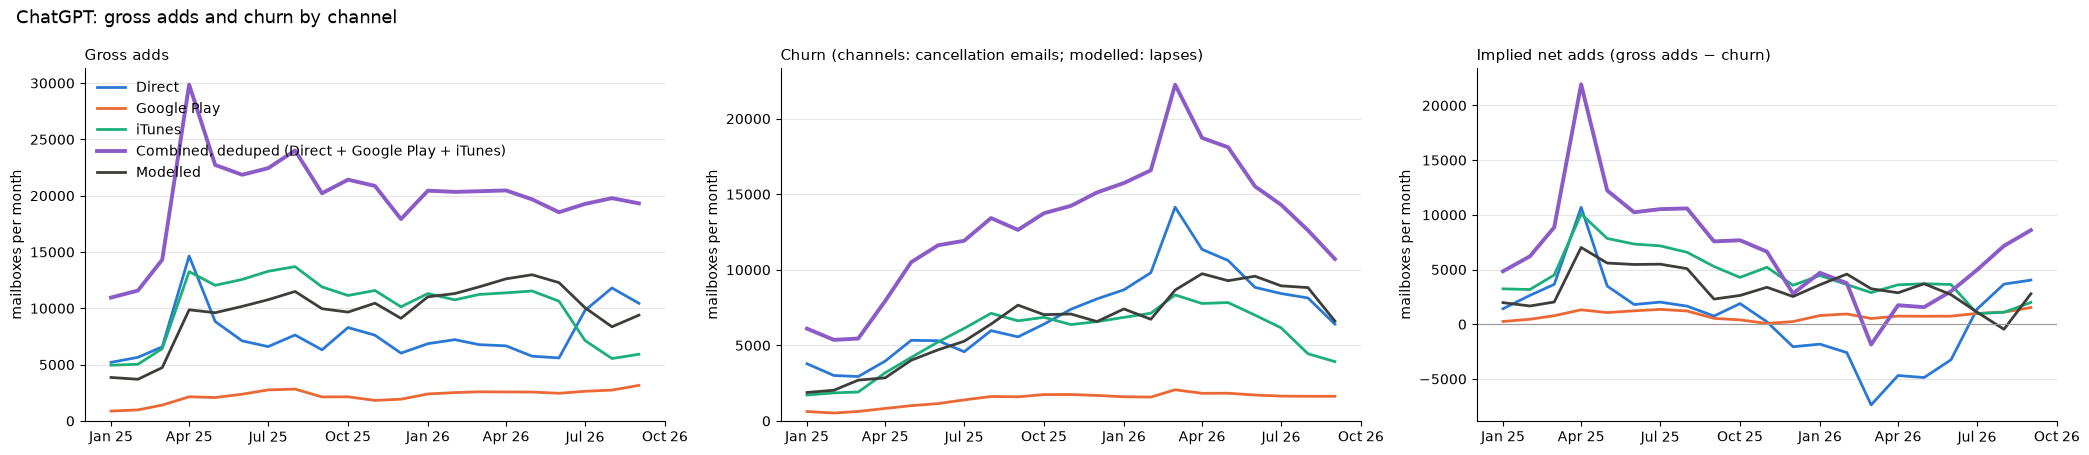

,gross_adds,churn,gross_adds_share,churn_share
Direct,161424.000,148739.000,0.384,0.502
Google Play,47108.000,30076.000,0.112,0.102
iTunes,211455.000,117224.000,0.503,0.396
"Combined, deduped",416400.000,272645.000,NaN,NaN
Combined / sum of those channels,0.991,0.921,NaN,NaN
Sum of channels the model reads (Google Play + iTunes),258563.000,147300.000,NaN,NaN
Modelled,203320.000,133988.000,NaN,NaN
Modelled / those channels,0.790,0.910,NaN,NaN


Correlation of monthly gross adds across channels (2025-01 to 2026-09)

,Direct,Google Play,iTunes,Combined,Modelled
Direct,1.00,0.35,0.00,0.62,0.07
Google Play,0.35,1.00,0.40,0.62,0.80
iTunes,0.00,0.40,1.00,0.78,0.74
Combined,0.62,0.62,0.78,1.00,0.68
Modelled,0.07,0.80,0.74,0.68,1.00


Correlation of monthly churn across channels (2025-01 to 2026-09)

,Direct,Google Play,iTunes,Combined,Modelled
Direct,1.00,0.83,0.80,0.95,0.83
Google Play,0.83,1.00,0.91,0.91,0.93
iTunes,0.80,0.91,1.00,0.94,0.84
Combined,0.95,0.91,0.94,1.00,0.86
Modelled,0.83,0.93,0.84,0.86,1.00


In [9]:
compare({"Direct": cg_dir, "Google Play": cg_gp, "iTunes": cg_it}, "ChatGPT: gross adds and churn by channel", model=model_tab("chatgpt"), model_covers=["Google Play", "iTunes"])

**Reading it**
- **Adds:** iTunes captures the most ChatGPT adds (about 50% since 2025-01), then direct (about 38%) and Google Play (about 11%). Direct and iTunes agree on the April 2025 spike (which coincides with the image-generation launch) but otherwise diverge. **From July 2026, iTunes adds fall by about half while direct adds rise by a similar amount.** iTunes renewal receipts stay flat over that period, so this looks like a shift of new sign-ups from in-app purchase to web checkout, not a data break. Monthly add correlations are weak (direct vs iTunes about 0).
- **Churn:** all three channels move together (correlations 0.80–0.91): a rise through 2025, a peak in March 2026, then a decline. Direct churn is large relative to direct adds. About half of direct cancellations have no ChatGPT sign-up email in the prior 400 days, which fits direct sign-up emails being captured less reliably than cancellations.
- **Modelled vs observed:** the model reads Google Play and iTunes only. ChatGPT direct is excluded because direct sends no renewals. Modelled adds follow Google Play and iTunes (correlation 0.80 and 0.74) at about 0.8 times their sum. Modelled adds come from the first paid receipt, while the iTunes line here also counts unpriced confirmations and restarts after a cancellation. The model also eases less than iTunes from July 2026, because Google Play keeps growing. Modelled churn tracks the cancellation-email lines closely (correlation 0.84–0.93), at about 0.9 times Google Play plus iTunes.

## 2. Claude

**Merchants found:** `Anthropic` (20127) and `Anthropic Cancellation` (20139). Both direct merchants exist, under the name Anthropic rather than Claude.

### 2a. Direct (`Anthropic`, `Anthropic Cancellation`)

In [10]:
m_dir = df.merchant_id.isin([20127, 20139])
patterns(m_dir, top=10)
sequences(m_dir, n=4, seed=1)

rows  priced_share  median_price
merchant_name          pattern                                             
Anthropic              payment           665052           1.0          20.0
                       pro subscription  110643           0.0           NaN
Anthropic Cancellation claude pro         37325           0.0           NaN
Anthropic              max subscription    7513           0.0           NaN
Anthropic Cancellation claude max          5567           0.0           NaN

,mailbox_id,order_date,merchant_name,description,item_price
1363069,1551169f-232a-3af5-ad4a-265e6b290b35,2026-07-13,Anthropic,Pro subscription,NaN
1363058,1551169f-232a-3af5-ad4a-265e6b290b35,2026-07-13,Anthropic,Payment,20.0
1363071,1551169f-232a-3af5-ad4a-265e6b290b35,2026-08-13,Anthropic,Payment,20.0
1363074,1551169f-232a-3af5-ad4a-265e6b290b35,2026-09-13,Anthropic,Payment,20.0
1363061,1551169f-232a-3af5-ad4a-265e6b290b35,2026-09-14,Anthropic Cancellation,Claude Pro,NaN
7340505,2f4b3c29-1138-3dbf-9244-e5a7a2fcd847,2026-05-18,Anthropic,Pro subscription,NaN
7340504,2f4b3c29-1138-3dbf-9244-e5a7a2fcd847,2026-05-18,Anthropic,Payment,20.0
7340506,2f4b3c29-1138-3dbf-9244-e5a7a2fcd847,2026-06-14,Anthropic Cancellation,Claude Pro,NaN
8146832,95984bdf-f4b1-31ca-a2c7-11bd3eb72dcf,2026-09-22,Anthropic,Pro subscription,NaN
8146831,95984bdf-f4b1-31ca-a2c7-11bd3eb72dcf,2026-10-14,Anthropic Cancellation,Claude Pro,NaN


- `Pro Subscription` / `Max Subscription` is an unpriced welcome, sent **at each sign-up** and at a tier change.
- `Payment` is priced and sent at sign-up and **every renewal**: $20 Pro, $100 Max 5x, $200 Max 20x. Other amounts ($5, $10, $45, $25…) are API or usage credits.
- `Anthropic Cancellation` sends `Claude Pro` / `Claude Max` once per cancellation. About 1.5% of cancellations are tier switches (e.g. `Claude Max` cancelled within 3 days of a `Pro Subscription` welcome).

**Filters used**
- Gross adds: first in series of `Pro Subscription` / `Max Subscription` welcomes and `Payment` rows priced exactly $20, $100 or $200 (renewals keep the series going; credits are excluded).
- Churn: `Anthropic Cancellation` rows (`Claude Pro`, `Claude Max`), excluding cross-tier switches (a cancellation within 3 days of a welcome for the other tier).

In [11]:
ws = df[m_dir & df.d.isin(["pro subscription", "max subscription"])][["mailbox_id", "dt", "d"]]
cn = df[m_dir & (df.merchant_id == 20139)][["mailbox_id", "dt", "d"]].reset_index()
x = cn.merge(ws, on="mailbox_id", suffixes=("", "_w"))
switch_idx = x[((x.dt_w - x.dt).dt.days.abs() <= 3) & (x.d.str.split().str[-1] != x.d_w.str.split().str[0])]["index"].unique()
print(f"Claude direct cancellations: {len(cn):,}; cross-tier switches excluded: {len(switch_idx):,} ({len(switch_idx) / len(cn):.1%})")
cl_dir = build(m_dir, signup=df.d.isin(["pro subscription", "max subscription"]) & (df.merchant_id == 20127),
               pay=(df.merchant_id == 20127) & (df.d == "payment") & df.item_price.isin([20, 100, 200]),
               cancel=(df.merchant_id == 20139) & ~df.index.isin(switch_idx))
show(cl_dir, "Claude direct: monthly gross adds and churn")

Claude direct cancellations: 46,124; cross-tier switches excluded: 624 (1.4%)


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Claude direct: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,1382,1473,1675,1026,1438,1899,2119,2085,1779,2535,2279,2341,4474,8313,16869,16668,12319,10219,8715,7184,7214,4892
churn,799,825,692,887,806,691,948,1012,1062,974,1142,1132,1275,1473,1913,3178,3914,3813,4214,4078,4002,2286


### 2b. Google Play

In [12]:
m_gp = (df.channel == "gp") & has(r"\bclaude\b|anthropic")
patterns(m_gp, top=8)
sequences(m_gp, n=4, seed=1)

rows  priced_share  median_price
merchant_name            pattern                                                                                                                                 
Google Play              claude pro subscription (claude by anthropic) auto-renewing subscription                               15176          1.00         20.00
                         claude max (claude by anthropic) auto-renewing subscription                                              932          1.00        125.00
                         claude max (claude by anthropic)                                                                         378          0.62        125.00
Google Play Cancellation your claude by anthropic subscription from anthropic, pbc on google play will be canceled on sep #, #    335          0.00           NaN
                         your claude by anthropic subscription from anthropic, pbc on google play will be canceled on aug #, #    322          0.00           NaN
                         your claude by anthropic subscription from anthropic, pbc on google play will be canceled on jun #, #    309          0.00           NaN
                         your claude by anthropic subscription from anthropic, pbc on google play will be canceled on jul #, #    301          0.00           NaN
                         your claude by anthropic subscription from anthropic, pbc on google play will be canceled on may #, #    300          0.00           NaN
                         claude by anthropic subscription from anthropic, pbc on google play has been canceled.                   274          0.00           NaN
                         your claude by anthropic subscription from anthropic, pbc on google play will be canceled on oct #, #    268          0.00           NaN
                         your claude by anthropic subscription from anthropic, pbc on google play will be canceled on apr #, #    244          0.00           NaN
Google Play              vicoa pro weekly (vibe code: claude and codex ai) auto-renewing subscription                              13          1.00          4.99
                         vicoa pro weekly (vicoa: claude code & codex ide) auto-renewing subscription                               2          1.00          4.99
                         claude by anthropic                                                                                        2          0.00          0.00
                         claude by anthropic digital book purchase                                                                  2          1.00          0.99
                         # ai prompts for k-# math teachers use in chatgpt, gemini, claude, grok & meta ai                          2          0.00          0.00

,mailbox_id,order_date,merchant_name,description,item_price
9902677,2b3332aa-6a4b-3128-b556-498b6ec7916e,2026-05-10,Google Play Cancellation,"Your Claude by Anthropic subscription from Anthropic, PBC on Google Play has been cancelled.",NaN
3447559,a37b1f2d-2a48-3e57-885c-b62c1414c012,2026-04-04,Google Play,Claude Pro Subscription (Claude by Anthropic) Auto-renewing subscription,20.0
3447545,a37b1f2d-2a48-3e57-885c-b62c1414c012,2026-05-04,Google Play,Claude Pro Subscription (Claude by Anthropic) Auto-renewing subscription,20.0
3447526,a37b1f2d-2a48-3e57-885c-b62c1414c012,2026-06-04,Google Play,Claude Pro Subscription (Claude by Anthropic) Auto-renewing subscription,20.0
3447540,a37b1f2d-2a48-3e57-885c-b62c1414c012,2026-06-30,Google Play,Claude Max (Claude by Anthropic),125.0
3447517,a37b1f2d-2a48-3e57-885c-b62c1414c012,2026-07-08,Google Play Cancellation,"Your Claude by Anthropic subscription from Anthropic, PBC on Google Play will be canceled on Aug 1, 2026",NaN
3447555,a37b1f2d-2a48-3e57-885c-b62c1414c012,2026-07-25,Google Play Cancellation,Claude by Anthropic (Claude Max) subscription will end on Aug 1,NaN
3447565,a37b1f2d-2a48-3e57-885c-b62c1414c012,2026-08-21,Google Play,Claude Pro Subscription (Claude by Anthropic) Auto-renewing subscription,20.0
3447519,a37b1f2d-2a48-3e57-885c-b62c1414c012,2026-08-21,Google Play,Claude Max (Claude by Anthropic),125.0
3447539,a37b1f2d-2a48-3e57-885c-b62c1414c012,2026-10-05,Google Play,Claude Max (Claude by Anthropic) Auto-renewing subscription,125.0


The structure matches ChatGPT on Google Play. `Claude Pro Subscription (Claude by Anthropic) Auto-renewing subscription` (and `Claude Max …`) is priced and sent at sign-up and **each renewal**. Cancellations read `Your Claude by Anthropic subscription from Anthropic, PBC … will be canceled on…`, `… has been canceled.` and `Claude by Anthropic (Claude Pro subscription) subscription will end on…`. Third-party apps (`Vicoa`, `Vibe code`, books about Claude Monet) also match the regex.

**Filters used**
- Gross adds: `Google Play` rows matching `\(claude by anthropic\) auto-renewing subscription`. The first in each series is the add.
- Churn: `Google Play Cancellation` rows mentioning `claude by anthropic`.

In [13]:
cl_gp = build(m_gp, signup=None, pay=GP_PAY & has(r"\(claude by anthropic\) auto-renewing subscription"),
              cancel=(df.merchant_id == 3452) & has(r"claude by anthropic"))
show(cl_gp, "Claude Google Play: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Claude Google Play: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,47,38,73,52,63,83,79,58,64,102,125,111,123,261,600,678,598,487,446,383,347,277
churn,35,28,43,41,44,57,58,68,55,64,85,80,91,115,179,295,297,331,357,312,364,218


### 2c. iTunes (App Store)

In [14]:
m_it = (df.channel == "itunes") & has(r"^claude by anthropic")
patterns(m_it, top=10)
sequences(m_it, n=4, seed=1)

rows  priced_share  median_price
merchant_name       pattern                                                                                      
iTunes              claude by anthropic : claude pro - monthly (monthly)        63524           1.0         20.00
                    claude by anthropic claude pro - monthly $#.# /month        16957           0.0           NaN
iTunes Cancellation claude by anthropic claude pro - monthly (# month)           9875           1.0         20.00
iTunes              claude by anthropic : claude max #x - monthly (monthly)      5744           1.0        124.99
                    claude by anthropic : claude pro - annual (annual)           1715           1.0        214.99
                    claude by anthropic claude pro - annual $#.# /year           1578           0.0           NaN
                    claude by anthropic claude pro - monthly usd #.# /month      1384           0.0           NaN
iTunes Cancellation claude by anthropic claude max #x - monthly (# month)         728           1.0        124.99
iTunes              claude by anthropic claude max #x - monthly $#.# /month       442           0.0           NaN
                    claude by anthropic : usage credits (#)                       421           1.0         45.00
                    claude by anthropic : claude pro - annual (yearly)            184           1.0        214.99
                    claude by anthropic claude max #x - monthly usd #.# /month    126           0.0           NaN
iTunes Cancellation claude by anthropic claude pro - annual (# year)               30           1.0        214.99
                    claude by anthropic claude pro - annual (# month)              10           1.0         72.50
                    claude by anthropic claude pro - monthly (# year)               1           1.0        214.99

,mailbox_id,order_date,merchant_name,description,item_price
11109776,89d250eb-7db4-3e36-a1e4-f18809bd94d9,2026-01-29,iTunes,Claude by Anthropic Claude Pro - Monthly $20.00 /month,NaN
11109747,89d250eb-7db4-3e36-a1e4-f18809bd94d9,2026-02-04,iTunes,Claude by Anthropic : Claude Pro - Monthly (Monthly),20.00
11109767,89d250eb-7db4-3e36-a1e4-f18809bd94d9,2026-02-12,iTunes Cancellation,Claude by Anthropic Claude Pro - Monthly (1 month),20.00
11109755,89d250eb-7db4-3e36-a1e4-f18809bd94d9,2026-05-05,iTunes,Claude by Anthropic : Claude Pro - Monthly (Monthly),20.00
11109754,89d250eb-7db4-3e36-a1e4-f18809bd94d9,2026-06-06,iTunes,Claude by Anthropic : Claude Pro - Monthly (Monthly),20.00
11109772,89d250eb-7db4-3e36-a1e4-f18809bd94d9,2026-08-07,iTunes,Claude by Anthropic : Claude Pro - Monthly (Monthly),20.00
11109751,89d250eb-7db4-3e36-a1e4-f18809bd94d9,2026-09-07,iTunes,Claude by Anthropic : Claude Pro - Monthly (Monthly),20.00
11109757,89d250eb-7db4-3e36-a1e4-f18809bd94d9,2026-10-07,iTunes,Claude by Anthropic : Claude Pro - Monthly (Monthly),20.00
1184374,8b64c5e9-b751-384b-a3e7-f4a1cecdb57d,2026-04-17,iTunes,Claude by Anthropic Claude Pro - Monthly $20.00 /month,NaN
1184375,8b64c5e9-b751-384b-a3e7-f4a1cecdb57d,2026-04-21,iTunes,Claude by Anthropic : Claude Pro - Monthly (Monthly),20.00


The structure matches ChatGPT on iTunes: an unpriced confirmation `Claude by Anthropic Claude Pro - Monthly $20.00 /month` at sign-up, and a priced `Claude by Anthropic : Claude Pro - Monthly (Monthly)` at sign-up and each renewal. There are annual (`/year`, `(Annual)`, `(Yearly)`) and Max 5x variants. `Usage credits` are one-off purchases. Cancellations read `Claude by Anthropic Claude Pro - Monthly (1 month)`.

**Filters used**
- Gross adds: the first in a series of confirmations or priced subscription receipts for the `Claude by Anthropic` app. Usage credits are excluded, and annual plans use the 400-day window.
- Churn: `iTunes Cancellation` rows starting `claude by anthropic`. This excludes third-party Claude Code IDE apps.

In [15]:
cl_it = build(m_it, signup=(df.merchant_id == 5) & IT_SIGNUP, pay=(df.merchant_id == 5) & IT_PAY & ~has("credits"),
              cancel=(df.merchant_id == 20122), annual=IT_ANNUAL)
show(cl_it, "Claude iTunes: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Claude iTunes: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,146,177,179,155,193,223,184,213,206,306,337,331,494,1520,3752,4226,3079,2422,2060,1879,1568,1060
churn,81,59,78,95,82,126,126,146,130,141,198,163,186,285,494,1042,1245,1244,1268,1310,1275,637


### 2d. Claude: channel comparison

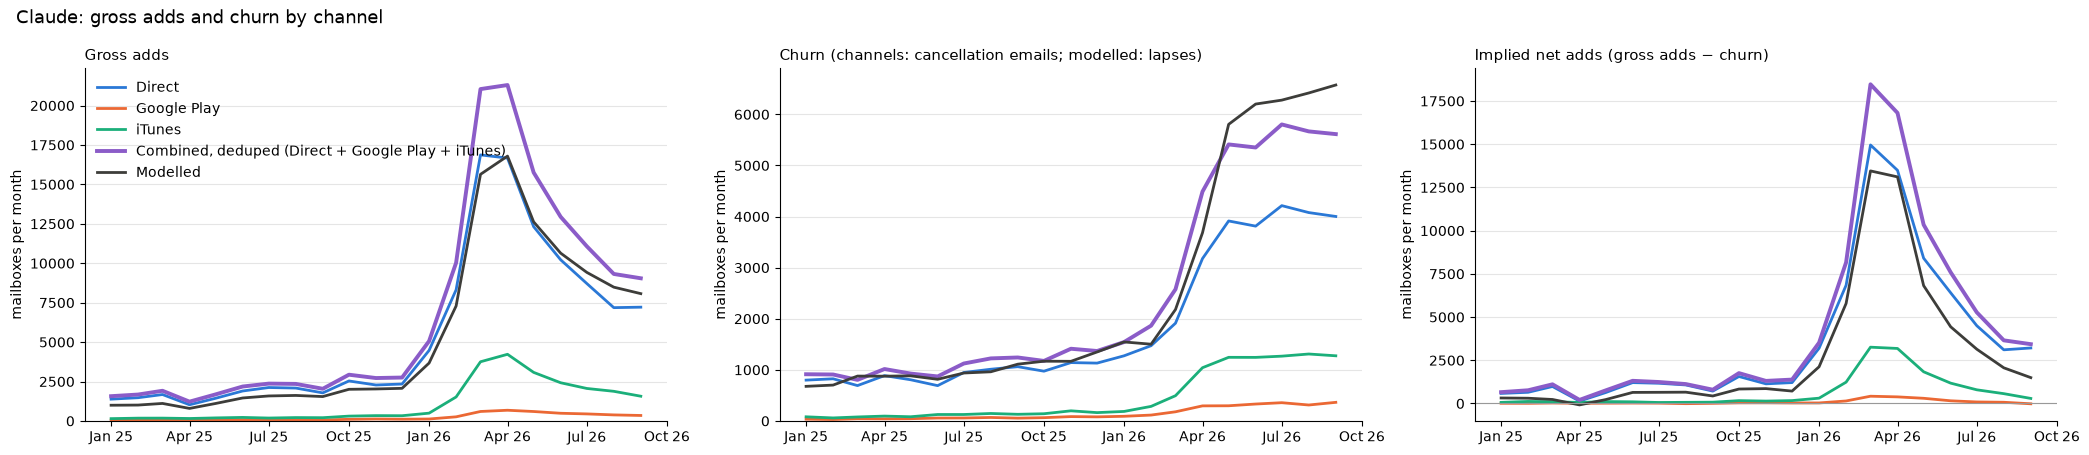

,gross_adds,churn,gross_adds_share,churn_share
Direct,114006.00,38830.000,0.800,0.752
Google Play,4818.00,2999.000,0.034,0.058
iTunes,23650.00,9774.000,0.166,0.189
"Combined, deduped",140980.00,51311.000,NaN,NaN
Combined / sum of those channels,0.99,0.994,NaN,NaN
Sum of channels the model reads (Direct + Google Play + iTunes),142474.00,51603.000,NaN,NaN
Modelled,109952.00,51720.000,NaN,NaN
Modelled / those channels,0.77,1.000,NaN,NaN


Correlation of monthly gross adds across channels (2025-01 to 2026-09)

,Direct,Google Play,iTunes,Combined,Modelled
Direct,1.00,0.97,0.99,1.00,0.99
Google Play,0.97,1.00,0.99,0.98,0.99
iTunes,0.99,0.99,1.00,0.99,1.00
Combined,1.00,0.98,0.99,1.00,1.00
Modelled,0.99,0.99,1.00,1.00,1.00


Correlation of monthly churn across channels (2025-01 to 2026-09)

,Direct,Google Play,iTunes,Combined,Modelled
Direct,1.00,0.99,1.00,1.00,0.99
Google Play,0.99,1.00,0.99,0.99,0.97
iTunes,1.00,0.99,1.00,1.00,0.99
Combined,1.00,0.99,1.00,1.00,0.99
Modelled,0.99,0.97,0.99,0.99,1.00


In [16]:
compare({"Direct": cl_dir, "Google Play": cl_gp, "iTunes": cl_it}, "Claude: gross adds and churn by channel", model=model_tab("claude"))

**Reading it**
- **The trends are almost identical across channels:** monthly correlations are 0.97–1.00 for both adds and churn. All three show the step-up from January 2026, a peak in March–April 2026, and a decline since.
- **Direct dominates:** about 80% of adds and 75% of churn, against iTunes at about 17–19% and Google Play at 3–6%. Any channel tracks the Claude trend well, but direct carries most of the volume.
- **Modelled vs observed:** the model reads all three channels and matches them almost perfectly (correlation 0.97–1.00). Modelled adds are about 0.77 times the sum of the channel lines, because the channel view counts a mailbox again in each channel it uses and restarts a series after a cancellation. Modelled churn equals the sum of cancellations over the period (ratio 1.00).

## 3. Gemini

**Merchants found:** no `Gemini` merchant. Gemini consumer plans are sold as **Google One** AI plans (`Google AI Plus / Pro / Ultra`, formerly `Google One AI Premium`), under `Google One` (20187) and `Google One Cancellation` (20191). Google One also sells storage-only plans (`100 GB`, `2 TB`…), which are excluded here. From January 2026, the 2 TB plan has included AI Plus features in some markets, so a plan is counted only when its name says AI.

### 3a. Direct (`Google One`, `Google One Cancellation`)

In [17]:
m_dir = df.merchant_id.isin([20187, 20191])
G_AI = r"google ai|ai premium|ai pro\b|ai plus|ai ultra"
patterns(m_dir & has(G_AI), top=12)

rows  priced_share  median_price
merchant_name           pattern                                                                                               
Google One              welcome to google ai pro plan # tb of google one storage             44772           0.0           NaN
Google One Cancellation google ai pro plan has ended                                         39576           0.0           NaN
Google One              welcome to google ai pro # tb of storage                             34231           0.0           NaN
                        welcome to google one ai pro # tb of storage                         23379           0.0           NaN
Google One Cancellation google one ai premium plan has ended                                 21964           0.0           NaN
Google One              welcome to google ai plus # gb of storage                            11960           0.0           NaN
                        welcome to google one ai premium plan # tb of storage                11841           0.0           NaN
Google One Cancellation google ai pro plan has been canceled                                 11675           0.0           NaN
                        google ai plus plan has ended                                         9747           0.0           NaN
Google One              welcome to google one ai plus # gb of storage                         9395           0.0           NaN
                        welcome to google one ai plus more access to google ai                8040           0.0           NaN
                        welcome to google ai plus # tb of storage                             6937           0.0           NaN
Google One Cancellation google one ai premium plan has been canceled                          6553           0.0           NaN
                        google ai pro trial has ended                                         6483           0.0           NaN
                        google ai plan has ended                                              5069           0.0           NaN
Google One              welcome to google one ai pro higher access to google ai               4010           0.0           NaN
                        welcome to google one ai plus # tb of storage                         2504           0.0           NaN
                        welcome to google ai pro back up your memories, and share your plan   1594           0.0           NaN
                        welcome to google one ai premium # tb of storage                      1516           0.0           NaN
Google One Cancellation google ai pro plan has been cancelled                                 1033           0.0           NaN
                        google one ai premium plan has been cancelled                          438           0.0           NaN
                        google ai ultra plan has ended                                         408           0.0           NaN
                        google ai ultra plan has been canceled                                 220           0.0           NaN
                        google ai plus trial has ended                                         196           0.0           NaN

- `Google One` sends **welcome emails only**, all unpriced: `Welcome to Google AI Pro …`, `Welcome to Google One AI Premium …`, `Welcome back to Google One …`. There are no payment receipts, so the direct channel is sign-up only.
- `Google One Cancellation` sends `Google AI Pro plan has ended`, `… has been canceled`, `Google AI Pro trial has ended`, and similar.
- **Google sends these emails whatever the billing channel.** About 64% of AI welcome emails come within 5 days of a Google Play AI receipt for the same mailbox, and about 2% within 5 days of an iTunes one. "Direct" for Gemini is therefore mostly Google Play subscribers seen through a second email, not a separate channel. A **direct-only** variant drops welcomes and cancellations that have a store AI receipt for the same mailbox within ±5 days (welcomes) or in the 75 days before (cancellations).

**Filters used**
- Gross adds: `Google One` rows starting `welcome` that name an AI plan (`google ai|ai premium|ai pro|ai plus|ai ultra`).
- Churn: `Google One Cancellation` rows that name an AI plan and say `ended`, `canceled` or `cancelled`. `… trial has ended` is excluded, because the trial was never paid.

In [18]:
g_store = df[(df.channel != "direct") & ~df.cancel_sender & has(G_AI) & df.priced][["mailbox_id", "dt"]].rename(columns={"dt": "sdt"})
def near_store(mask, before, after):
    x = df[mask][["mailbox_id", "dt"]].reset_index().merge(g_store, on="mailbox_id")
    d = (x.sdt - x.dt).dt.days
    return df.index.isin(x[(d >= -before) & (d <= after)]["index"].unique())
gw = (df.merchant_id == 20187) & has(r"^welcome") & has(G_AI)
gc = (df.merchant_id == 20191) & has(G_AI) & has(r"ended|cancell?ed") & ~has(r"trial has ended")
gm_dir = build(m_dir, signup=gw, pay=None, cancel=gc)
gm_dir_only = build(m_dir, signup=gw & ~near_store(gw, 5, 5), pay=None, cancel=gc & ~near_store(gc, 75, 0))
show(gm_dir, "Gemini direct (all Google One AI emails): monthly gross adds and churn")
show(gm_dir_only, "Gemini direct-only (no store AI receipt nearby): monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Gemini direct (all Google One AI emails): monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,2999,2738,1981,2976,8753,9931,6522,6715,8913,6942,8954,10196,7149,6184,6453,5174,5283,7832,8639,8907,9323,5920
churn,3651,3358,3209,2831,3730,4584,4671,4256,4115,4173,3643,4363,4304,3490,3758,3402,2817,3630,3509,3565,3876,2271


**Gemini direct-only (no store AI receipt nearby): monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,2801,2478,1733,2695,8028,9001,5684,5958,8111,6039,7748,8561,5108,3784,3866,2720,2225,2706,2955,3454,4160,2572
churn,2819,2567,2359,1872,2697,3576,3421,2947,2932,2954,2558,3055,2833,2132,2092,1889,1529,2123,1455,1428,1786,828


### 3b. Google Play

In [19]:
m_gp = (df.channel == "gp") & has(r"google one|google ai|gemini")
patterns(m_gp, top=10)
sequences(m_gp & has(r"google one"), n=3, seed=5)

rows  priced_share  median_price
merchant_name            pattern                                                                                                                                            
Google Play              # gb (google one) (by google llc) auto-renewing subscription                                                    4385833          1.00          1.99
                         # tb (google one) (by google llc) auto-renewing subscription                                                     453429          1.00          9.99
                         google ai pro (# tb) (google one) (by google llc) auto-renewing subscription                                     242773          1.00         19.99
                         google ai plus (# tb) (google one) (by google llc) auto-renewing subscription                                    133127          1.00          9.99
                         # gb (google one)                                                                                                 67580          0.93          2.99
Google Play Cancellation google one subscription from google llc on google play has been canceled.                                         59884          0.00           NaN
Google Play              google ai plus (# gb) (google one) (by google llc) auto-renewing subscription                                     33305          1.00          4.99
                         google one ai premium (google one) (by google llc) auto-renewing subscription                                     33217          1.00         19.99
                         # tb (google one)                                                                                                 28034          0.91          2.99
                         google ai plus (#gb) (google one) (by google llc) auto-renewing subscription                                      13551          1.00          3.99
                         your trial will end on sep #, #. you will be automatically charged the subscription cost (currently $#.#/month    10566          0.00          0.00
Google Play Cancellation your google one subscription from google llc on google play will be canceled on sep #, #                          10076          0.00           NaN
                         your google one subscription from google llc on google play will be canceled on aug #, #                           9351          0.00           NaN
                         your google one subscription from google llc on google play will be canceled on feb #, #                           9194          0.00           NaN
                         your google one subscription from google llc on google play will be canceled on jul #, #                           8974          0.00           NaN
                         your google one subscription from google llc on google play will be canceled on jun #, #                           8769          0.00           NaN
                         your google one subscription from google llc on google play will be canceled on may #, #                           8151          0.00           NaN
                         your google one subscription from google llc on google play will be canceled on apr #, #                           8151          0.00           NaN
                         your google one subscription from google llc on google play will be canceled on mar #, #                           8064          0.00           NaN
                         your google one subscription from google llc on google play will be canceled on oct #, #                           7977          0.00           NaN

,mailbox_id,order_date,merchant_name,description,item_price
10658092,4b77443b-5042-3699-9911-d875265c88be,2025-12-31,Google Play Cancellation,"Your Google One subscription from Google LLC on Google Play will be canceled on Jan 2, 2026",NaN
10658088,4b77443b-5042-3699-9911-d875265c88be,2026-03-13,Google Play Cancellation,"Your Google One subscription from Google LLC on Google Play will be canceled on Mar 15, 2026",NaN
3362126,6bdcde7d-092f-30c0-bfd6-4185d988b417,2026-02-13,Google Play,100 GB (Google One) (by Google LLC) Auto-renewing subscription,0.49
3362125,6bdcde7d-092f-30c0-bfd6-4185d988b417,2026-03-13,Google Play,100 GB (Google One) (by Google LLC) Auto-renewing subscription,0.49
3362121,6bdcde7d-092f-30c0-bfd6-4185d988b417,2026-04-08,Google Play Cancellation,"Your Google One subscription from Google LLC on Google Play will be canceled on Apr 13, 2026",NaN
3362120,6bdcde7d-092f-30c0-bfd6-4185d988b417,2026-04-13,Google Play,100 GB (Google One) (by Google LLC) Auto-renewing subscription,0.49
3362116,6bdcde7d-092f-30c0-bfd6-4185d988b417,2026-05-13,Google Play,100 GB (Google One) (by Google LLC) Auto-renewing subscription,1.99
3362119,6bdcde7d-092f-30c0-bfd6-4185d988b417,2026-06-13,Google Play,100 GB (Google One) (by Google LLC) Auto-renewing subscription,1.99
3362118,6bdcde7d-092f-30c0-bfd6-4185d988b417,2026-07-13,Google Play,100 GB (Google One) (by Google LLC) Auto-renewing subscription,1.99
3362117,6bdcde7d-092f-30c0-bfd6-4185d988b417,2026-08-13,Google Play,100 GB (Google One) (by Google LLC) Auto-renewing subscription,1.99


- `Google AI Pro (2 TB) (Google One) (by Google LLC) Auto-renewing subscription` (and AI Plus, AI Premium, AI Ultra) is priced and sent at sign-up and **each renewal**. Storage-only plans such as `100 GB (Google One) … Auto-renewing` use the same format.
- Cancellations mostly **don't name the plan**: `Google One subscription from Google LLC on Google Play has been canceled` / `… will be canceled on <date>`. Only the `Google One (Google AI Pro (2 TB)) subscription will end on…` reminder names it (about 8% of rows).

**Filters used**
- Gross adds: `Google Play` rows with `(google one)` and `auto-renewing subscription` that name an AI plan. The first in each series is the add, so a switch from storage to AI counts as an add here.
- **Rename exclusion:** in May and June 2026, Google renamed the 2 TB storage plan ($9.99) to `Google AI Plus (2 TB)` for existing subscribers, so their next receipt carries an AI plan name at the same price. Without a correction, about 30k storage subscribers show up as AI adds in those two months. An AI add is dropped if the mailbox had a Google Play storage receipt **at the same price** in the 45 days before it. Paid upgrades from storage, at a different price, still count.
- Churn: `Google Play Cancellation` rows mentioning `google one`. A row counts as AI churn if it names an AI plan, or if the mailbox's last Google Play Google One receipt before it (within 75 days) was an AI plan.

In [20]:
gp_g1 = df[GP_PAY & has(r"\(google one\)")][["mailbox_id", "dt", "d", "item_price"]].sort_values("dt")
gp_g1["ai"] = gp_g1.d.str.contains(G_AI)
gcan = df[(df.merchant_id == 3452) & has(r"google one")][["mailbox_id", "dt", "d"]].reset_index().sort_values("dt")
last = pd.merge_asof(gcan, gp_g1.rename(columns={"dt": "pdt", "d": "pd"}), left_on="dt", right_on="pdt", by="mailbox_id",
                     direction="backward", tolerance=pd.Timedelta(days=75))
ai_cancel = last[last.d.str.contains(G_AI) | last.ai.fillna(False).astype(bool)]["index"]
print(f"Google Play Google One cancellations: {len(gcan):,}; attributed to AI plans: {len(ai_cancel):,} "
      f"(named AI {gcan.d.str.contains(G_AI).sum():,}; via last receipt {len(ai_cancel) - gcan.d.str.contains(G_AI).sum():,})")
gtab, gadds, gchurn = build(m_gp, signup=None, pay=GP_PAY & has(r"\(google one\)") & has(G_AI), cancel=df.index.isin(ai_cancel), parts=True)
# rename exclusion: same-price storage receipt in the 45 days before the AI add
price = gp_g1[gp_g1.ai].drop_duplicates(["mailbox_id", "dt"])[["mailbox_id", "dt", "item_price"]]
ga = gadds.merge(price, on=["mailbox_id", "dt"], how="left").sort_values("dt")
st = gp_g1[~gp_g1.ai][["mailbox_id", "dt", "item_price"]].rename(columns={"dt": "sdt", "item_price": "sprice"}).sort_values("sdt")
ga = pd.merge_asof(ga, st, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=45))
ga["is_rename"] = ga.sprice.notna() & (ga.sprice.round(2) == ga.item_price.round(2))
print("AI adds dropped as same-price storage renames, by month:")
display(ga[ga.is_rename].assign(month=ga.dt.dt.to_period("M")).groupby("month").size().rename("renames").loc["2025-01":].to_frame().T)
gm_gp = R.monthly(ga[~ga.is_rename], gchurn); gm_gp.attrs = gtab.attrs
EVENTS[id(gm_gp)] = (ga[~ga.is_rename][["mailbox_id", "dt", "row"]], gchurn[["mailbox_id", "dt", "row"]], EVENTS[id(gtab)][2])
show(gm_gp, "Gemini Google Play: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\835037946.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  direction="backward", tolerance=pd.Timedelta(days=75))


Google Play Google One cancellations: 275,046; attributed to AI plans: 50,228 (named AI 22,639; via last receipt 27,589)


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\835037946.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ga = pd.merge_asof(ga, st, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=45))


AI adds dropped as same-price storage renames, by month:


month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
renames,5,5,8,12,37,28,39,29,50,125,184,288,386,351,210,223,8850,17322,938,830,1046,886


**Gemini Google Play: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,1784,1912,1629,1392,2144,2623,2399,2021,2002,2048,2201,2954,3502,3638,3282,3030,3648,5925,5721,6341,6731,3717
churn,710,708,713,705,960,1480,1776,1929,1783,1732,1540,1816,2007,1725,2012,2118,2049,1922,2321,2544,3127,1500


### 3c. iTunes (App Store)

In [21]:
m_it = (df.channel == "itunes") & has(G_AI)
patterns(m_it, top=12)
sequences(m_it, n=3, seed=5)

rows  priced_share  median_price
merchant_name       pattern                                                                                         
iTunes              google gemini : google ai pro (# tb) (monthly)                  3970           1.0         19.99
                    google ai pro (# tb) : google ai pro (# tb) (monthly)           3623           1.0         19.99
iTunes Cancellation google gemini google ai pro (# tb) (# month)                    2912           1.0         19.99
iTunes              google ai plus : google ai plus (monthly)                       2703           1.0          4.99
                    google ai plus                                                  1689           1.0          4.99
                    google photos: backup & edit : google ai plus (# tb) (monthly)  1551           1.0          9.99
                    google photos: backup & edit : google ai pro (# tb) (monthly)   1240           1.0         19.99
                    gmail - email by google : google ai pro (# tb) (monthly)         869           1.0         19.99
                    google gemini : google ai plus (#gb) (monthly)                   817           1.0          3.99
                    google ai pro (# tb)                                             804           1.0          9.99
                    google gemini google ai pro (# tb) $#.# /month                   707           0.0           NaN
                    gmail - email by google : google ai plus (# tb) (monthly)        611           1.0          9.99
                    gmail - email by google google ai plus $#.# /month               558           0.0           NaN
iTunes Cancellation google gemini google ai plus (# month)                           323           1.0          4.99
                    google gemini google one ai premium (# tb) (# month)             262           1.0         19.99
                    google gemini google ai plus (#gb) (# month)                     205           1.0          7.99
                    google notebooklm google ai pro (# tb) (# month)                 148           1.0         19.99
                    gmail - email by google google ai pro (# tb) (# month)           117           1.0         19.99
                    gmail - email by google google ai plus (# month)                 117           1.0          4.99
                    google photos: backup & edit google ai pro (# tb) (# month)       89           1.0         19.99
                    google one google ai pro (# tb) (# month)                         68           1.0         19.99
                    google notebooklm google ai plus (#gb) (# month)                  64           1.0          7.99
                    gemini notebook google ai plus (# gb) (# month)                   49           1.0          4.99
                    google photos: backup & edit google ai plus (# month)             41           1.0          4.99

,mailbox_id,order_date,merchant_name,description,item_price
1530815,3d65aa79-973d-3062-ad32-df6f59e0668b,2026-09-10,iTunes,Google Flow Google AI Pro (5 TB) $19.99 /month,NaN
1530821,3d65aa79-973d-3062-ad32-df6f59e0668b,2026-09-15,iTunes,Google AI Pro (5 TB),1.99
1530812,3d65aa79-973d-3062-ad32-df6f59e0668b,2026-09-25,iTunes Cancellation,Google Flow Google AI Pro (5 TB) (1 month),19.99
11926343,794e13f3-e6a9-3c15-aedd-cfc59d617e04,2026-02-21,iTunes,"Google Gemini Google AI Plus (200GB) $3.99 every month for 2 months, starting Feb 20, 2026 $7.99 /month, s...",NaN
11926324,794e13f3-e6a9-3c15-aedd-cfc59d617e04,2026-02-24,iTunes,Google Gemini : Google AI Plus (200GB) (Monthly),3.99
11926346,794e13f3-e6a9-3c15-aedd-cfc59d617e04,2026-03-06,iTunes Cancellation,Google Gemini Google AI Plus (200GB) (1 month),7.99
9079007,c23a4568-4ffd-3400-beb8-b1940e69f911,2025-09-29,iTunes,"Google Gemini Google AI Pro (2 TB) 1 month, starting Sep 29, 2025 free trial. Price: 19.99 /month, startin...",NaN
9079015,c23a4568-4ffd-3400-beb8-b1940e69f911,2026-01-08,iTunes,Google Gemini : Google AI Pro (2 TB) (Monthly),19.99
9079006,c23a4568-4ffd-3400-beb8-b1940e69f911,2026-01-14,iTunes Cancellation,Google Gemini Google AI Pro (2 TB) (1 month),19.99
9079012,c23a4568-4ffd-3400-beb8-b1940e69f911,2026-07-31,iTunes,Google Gemini Google AI Pro (5 TB) $19.99 /month,NaN


Google AI plans are sold in several Google iOS apps: `Google Gemini`, `Google One`, `Google Photos`, `Gmail`, `Google NotebookLM`. Each has an unpriced confirmation (`Google Gemini Google AI Pro (2 TB) $19.99 /month`) and a priced receipt per sign-up and renewal (`Google Gemini : Google AI Pro (2 TB) (Monthly)`). Some priced rows are bare `Google AI Plus` / `Google AI Pro (2 TB)` with no app name. Cancellations read `Google Gemini Google AI Pro (2 TB) (1 month)`. Storage-only (`Google One : 100 GB`) and third-party "Gemini" apps (duplicate finders, photo cleaners) don't name a Google AI plan, so the AI-plan filter drops them.

**Filters used**
- Gross adds: the first in a series of confirmations or priced receipts naming a Google AI plan (`google ai|ai premium|ai pro|ai plus|ai ultra`). Bare priced `Google AI …` rows count as paid.
- Churn: `iTunes Cancellation` rows naming a Google AI plan.

In [22]:
gm_it = build(m_it, signup=(df.merchant_id == 5) & IT_SIGNUP,
              pay=(df.merchant_id == 5) & df.priced & (IT_PAY | has(r"^google ai (plus|pro|ultra)")),
              cancel=(df.merchant_id == 20122), annual=IT_ANNUAL)
show(gm_it, "Gemini iTunes: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Gemini iTunes: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,80,73,64,72,106,147,151,118,117,150,276,429,473,336,494,415,725,960,509,489,498,539
churn,62,55,50,77,96,314,251,225,194,299,197,384,248,261,303,294,304,232,202,211,237,189


### 3d. Gemini: channel comparison

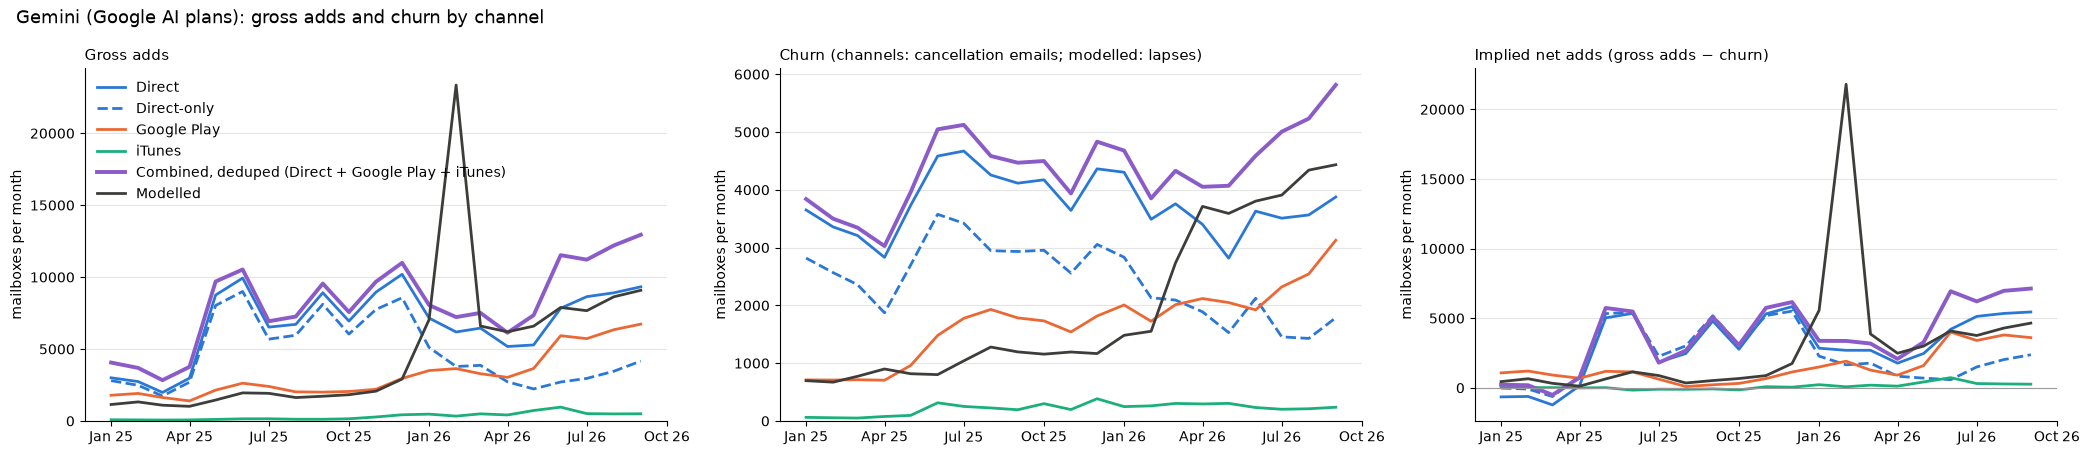

,gross_adds,churn,gross_adds_share,churn_share
Direct,142564.00,78935.000,0.451,0.464
Direct-only,99815.00,51024.000,0.316,0.300
Google Play,66927.00,35677.000,0.212,0.210
iTunes,6682.00,4496.000,0.021,0.026
"Combined, deduped",170676.00,91789.000,NaN,NaN
Combined / sum of those channels,0.79,0.771,NaN,NaN
Sum of channels the model reads (Google Play + iTunes),73609.00,40173.000,NaN,NaN
Modelled,103093.00,41247.000,NaN,NaN
Modelled / those channels,1.40,1.030,NaN,NaN


Correlation of monthly gross adds across channels (2025-01 to 2026-09)

,Direct,Direct-only,Google Play,iTunes,Combined,Modelled
Direct,1.00,0.71,0.47,0.33,0.94,0.15
Direct-only,0.71,1.00,-0.27,-0.30,0.45,-0.29
Google Play,0.47,-0.27,1.00,0.78,0.72,0.57
iTunes,0.33,-0.30,0.78,1.00,0.54,0.50
Combined,0.94,0.45,0.72,0.54,1.00,0.27
Modelled,0.15,-0.29,0.57,0.50,0.27,1.00


Correlation of monthly churn across channels (2025-01 to 2026-09)

,Direct,Direct-only,Google Play,iTunes,Combined,Modelled
Direct,1.00,0.78,0.25,0.46,0.64,-0.28
Direct-only,0.78,1.00,-0.37,0.09,0.07,-0.77
Google Play,0.25,-0.37,1.00,0.67,0.81,0.80
iTunes,0.46,0.09,0.67,1.00,0.59,0.35
Combined,0.64,0.07,0.81,0.59,1.00,0.49
Modelled,-0.28,-0.77,0.80,0.35,0.49,1.00


In [23]:
compare({"Direct": gm_dir, "Direct-only": gm_dir_only, "Google Play": gm_gp, "iTunes": gm_it}, "Gemini (Google AI plans): gross adds and churn by channel",
        extra_styles={"Direct-only": {"color": COLORS["Direct"], "ls": "--"}}, model=model_tab("gemini"), model_covers=["Google Play", "iTunes"])

**Reading it**
- **Google Play and iTunes agree** (add correlation 0.78, churn 0.67): both rise from mid-2025, and Google Play adds rise again from June 2026, after the rename spike was removed. Google Play is about 10 times iTunes. Google's AI plans are mostly bought on Android or Google's web.
- **The Google One "direct" emails are not a clean third channel.** Most welcome emails duplicate store subscriptions, and many are probably free trials or promotional offers: the emails are unpriced, and about a quarter of direct cancellations have no welcome email in the prior 400 days. Removing the welcomes that match a store receipt gives a **direct-only** line that moves *against* the stores (correlation −0.27 for adds). That fits it being mostly promotional sign-ups rather than paid web subscriptions. Treat the direct lines as sign-up intent, not paid adds.
- **Modelled vs observed:** the model reads Google Play and iTunes and follows Google Play for adds (0.57) and churn (0.80). It differs in two places:
  - **February 2026 spike (about 23k).** The model counts the 2 TB storage plan as AI Plus from 2026-01-27, so about 19k existing 2 TB subscribers become `ai_plus_2tb_M` adds in February. The channel view drops the matching May–June 2026 rename instead. The two views treat the same 2 TB population differently, and one should be aligned with the other.
  - **Modelled churn rises above every channel from March 2026.** This follows from the larger 2 TB base the model carries.

## 4. Grok

**Merchants found: no direct Grok / xAI merchant, and no cancellation merchant.** I searched `items_v` merchant names (`grok`, `xai`, `x corp`, `twitter`) and descriptions (`\bgrok\b`, `supergrok`) outside the app stores. The only xAI-adjacent sender is `Twitter` (3677), whose rows are all an unpriced `Payment` with no plan name, so they can't be tied to Grok. X Premium+ (which includes Grok) is an X product and is not counted. **This section has Google Play and iTunes only.**

### 4a. Google Play

In [24]:
m_gp = (df.channel == "gp") & has(r"\bgrok\b|supergrok|super grok|x\.ai")
patterns(m_gp, top=10)
sequences(m_gp, n=3, seed=2)

rows  priced_share  median_price
merchant_name            pattern                                                                                                                                         
Google Play              supergrok (grok - ai chat & video) auto-renewing subscription                                                   3248           1.0         29.99
                         super grok (grok • smartest ai advisor) auto-renewing subscription                                              3193           1.0         29.99
                         supergrok (grok ai) auto-renewing subscription                                                                  2126           1.0         29.99
                         grok credits (grok ai)                                                                                          1929           1.0          4.99
                         your trial will end on mar #, #. you will be automatically charged the subscription cost (currently $#.#/month  1904           0.0          0.00
                         your trial will end on apr #, #. you will be automatically charged the subscription cost (currently $#.#/month  1250           0.0          0.00
                         grok credits (grok)                                                                                              868           1.0          4.99
                         your trial will end on feb #, #. you will be automatically charged the subscription cost (currently $#.#/month   864           0.0          0.00
Google Play Cancellation your grok - ai chat & video subscription from x.ai corp. on google play will be canceled on apr #, #             864           0.0           NaN
                         your grok • smartest ai advisor subscription from x.ai corp. on google play will be canceled on mar #, #         857           0.0           NaN
                         grok - ai chat & video subscription from x.ai corp. on google play has been canceled.                            827           0.0           NaN
                         your grok • smartest ai advisor subscription from x.ai corp. on google play will be canceled on feb #, #         746           0.0           NaN
Google Play              supergrok lite (grok - ai chat & video) auto-renewing subscription                                               722           1.0          9.99
                         supergrok lite (grok ai) auto-renewing subscription                                                              649           1.0          9.99
Google Play Cancellation your grok - ai chat & video subscription from x.ai corp. on google play will be canceled on jun #, #             643           0.0           NaN
                         your grok - ai chat & video subscription from x.ai corp. on google play will be canceled on may #, #             474           0.0           NaN
                         your grok - ai chat & video subscription from x.ai corp. on google play will be canceled on jul #, #             331           0.0           NaN
                         your grok ai subscription from x.ai corp. on google play will be canceled on sep #, #                            282           0.0           NaN
                         grok • smartest ai advisor subscription from x.ai corp. on google play has been canceled.                        276           0.0           NaN
                         your grok ai subscription from x.ai corp. on google play will be canceled on aug #, #                            258           0.0           NaN

,mailbox_id,order_date,merchant_name,description,item_price
9799008,3ad6652d-c36f-3d1c-9da8-1da8c418eaf4,2026-04-15,Google Play,"Your trial will end on Apr 18, 2026. You will be automatically charged the subscription cost (currently $2...",0.00
9799015,3ad6652d-c36f-3d1c-9da8-1da8c418eaf4,2026-04-18,Google Play,SuperGrok (Grok - AI Chat & Video) Auto-renewing subscription,29.99
9799014,3ad6652d-c36f-3d1c-9da8-1da8c418eaf4,2026-05-15,Google Play Cancellation,"Your Grok - AI Chat & Video subscription from X.AI CORP. on Google Play will be canceled on May 18, 2026",NaN
6744196,6da8bb38-e211-383b-af1b-edeb7a72f817,2026-03-30,Google Play,"Your trial will end on Apr 2, 2026. You will be automatically charged the subscription cost (currently $29...",0.00
6744194,6da8bb38-e211-383b-af1b-edeb7a72f817,2026-04-08,Google Play,SuperGrok (Grok - AI Chat & Video) Auto-renewing subscription,29.99
6744210,6da8bb38-e211-383b-af1b-edeb7a72f817,2026-04-08,Google Play Cancellation,"Your Grok - AI Chat & Video subscription from X.AI CORP. on Google Play will be canceled on May 2, 2026",NaN
6744186,6da8bb38-e211-383b-af1b-edeb7a72f817,2026-04-25,Google Play Cancellation,Grok - AI Chat & Video (SuperGrok) subscription will end on May 2,NaN
7822848,7fb47ba6-754a-307b-b421-b7c49eeff8b7,2026-10-12,Google Play,SuperGrok (Grok) Auto-renewing subscription,29.99
7822847,7fb47ba6-754a-307b-b421-b7c49eeff8b7,2026-10-12,Google Play Cancellation,"Your Grok subscription from SpaceXAI LLC on Google Play will be canceled on Jan 12, 2027",NaN
7822849,7fb47ba6-754a-307b-b421-b7c49eeff8b7,2026-10-17,Google Play,Grok Credits (Grok),99.99


xAI has published the app under several names (`Grok - AI Chat & Video`, `Grok – Smartest AI Advisor`, `Grok AI`, `Grok - AI Assistant`). Each sends a priced `SuperGrok (…) Auto-renewing subscription` (plus `SuperGrok Lite` / `Heavy`) at sign-up and **each renewal**. `Grok credits` are one-off. Free-trial notices (`Your trial will end on…`) are common for Grok. Cancellations read `Your <app> subscription from X.AI Corp. on Google Play will be canceled on…`, `… has been canceled.` and `Grok - AI Chat & Video (SuperGrok) subscription will end on…`.

**Filters used**
- Gross adds: `Google Play` rows matching `super ?grok` and `auto-renewing subscription`. The first in each series is the add.
- Churn: `Google Play Cancellation` rows mentioning `x.ai corp` or `(super ?grok`.

In [25]:
gk_gp = build(m_gp, signup=None, pay=GP_PAY & has(r"super ?grok") & has("auto-renewing subscription"),
              cancel=(df.merchant_id == 3452) & has(r"x\.ai corp|\(super ?grok"))
show(gk_gp, "Grok Google Play: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Grok Google Play: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,0,0,27,66,47,32,174,145,77,186,181,191,296,273,550,630,540,498,430,517,527,209
churn,0,0,6,32,39,50,72,114,80,120,104,167,240,794,1256,1190,797,807,711,427,392,70


### 4b. iTunes (App Store)

In [26]:
m_it = (df.channel == "itunes") & has(r"super ?grok")
patterns(m_it, top=12)
sequences(m_it, n=3, seed=2)

rows  priced_share  median_price
merchant_name       pattern                                                                                                                                       
iTunes              grok : supergrok (monthly)                                                                                   14947           1.0          30.0
                    grok - ai chat & video : supergrok (monthly)                                                                  9011           1.0          30.0
                    grok ai : supergrok (monthly)                                                                                 7783           1.0          30.0
iTunes Cancellation grok supergrok (# month)                                                                                      7237           1.0          30.0
                    grok - ai chat & video supergrok (# month)                                                                    5164           1.0          30.0
                    grok ai supergrok (# month)                                                                                   4616           1.0          30.0
iTunes              grok supergrok # days, starting jan #, # free trial. price: #.# /month, starting jan #, #                     2869           0.0           NaN
                    grok supergrok usd #.# /month                                                                                 2612           0.0           NaN
                    grok - ai chat & video supergrok # days, starting apr #, # free trial. price: #.# /month, starting apr #, #   2125           0.0           NaN
                    grok supergrok $#.# /month                                                                                    1974           0.0           NaN
                    grok supergrok # week, starting feb #, # free trial. price: #.# /month, starting feb #, #                     1358           0.0           NaN
                    supergrok supergrok # week, starting sep #, # free trial. price: $#.# /month, starting sep #, #               1163           0.0           NaN
                    grok - ai chat & video supergrok # days, starting may #, # free trial. price: #.# /month, starting may #, #   1105           0.0           NaN
                    grok supergrok # days, starting mar #, # free trial. price: #.# /month, starting mar #, #                     1067           0.0           NaN
                    grok - ai chat & video supergrok # days, starting mar #, # free trial. price: #.# /month, starting mar #, #   1048           0.0           NaN
iTunes Cancellation grok ai supergrok lite (# month)                                                                               296           1.0          10.0
                    grok - ai chat & video supergrok lite (# month)                                                                274           1.0          10.0
                    grok - ai assistant supergrok (# month)                                                                        139           1.0          40.0
                    grok ai supergrok heavy (# month)                                                                              106           1.0         300.0
                    grok - ai chat & video supergrok heavy (# month)                                                                96           1.0         300.0
                    grok supergrok heavy (# month)                                                                                  92           1.0         300.0
                    grok ai supergrok plus (# month)                                                                                58           1.0         100.0
                    grok - ai chat & video supergrok (# year)                                                                       35           1.0         300.0
                    grok supergrok (# year)            

,mailbox_id,order_date,merchant_name,description,item_price
12107397,16d38b82-be07-3c91-8bc0-b9657eca9c05,2025-12-17,iTunes,Grok : SuperGrok (Monthly),30.0
12107396,16d38b82-be07-3c91-8bc0-b9657eca9c05,2025-12-29,iTunes Cancellation,Grok SuperGrok (1 month),30.0
12107394,16d38b82-be07-3c91-8bc0-b9657eca9c05,2026-02-14,iTunes Cancellation,Grok SuperGrok (1 month),30.0
3562288,53d9a22c-8474-39d5-96bc-916123c28f0e,2026-08-29,iTunes,"SuperGrok SuperGrok 1 week, starting Aug 29, 2026 free trial. Price: $30.00 /month, starting Sep 5, 2026",NaN
3562283,53d9a22c-8474-39d5-96bc-916123c28f0e,2026-09-12,iTunes,Grok AI : SuperGrok (Monthly),30.0
3562285,53d9a22c-8474-39d5-96bc-916123c28f0e,2026-09-27,iTunes Cancellation,Grok AI SuperGrok (1 month),30.0
7324930,b3994c52-d765-3491-b94f-7cae70abf0eb,2026-04-24,iTunes,"Grok - AI Chat & Video SuperGrok 3 days, starting Apr 24, 2026 free trial. Price: 30.0 /month, starting Ap...",NaN
7324929,b3994c52-d765-3491-b94f-7cae70abf0eb,2026-04-27,iTunes Cancellation,Grok - AI Chat & Video SuperGrok (1 month),30.0
7324928,b3994c52-d765-3491-b94f-7cae70abf0eb,2026-07-22,iTunes,Grok AI : SuperGrok Lite (Monthly),10.0


The structure matches the other apps: an unpriced confirmation (`Grok SuperGrok $29.99 /month`), a priced `Grok : SuperGrok (Monthly)` at sign-up and each renewal, and `iTunes Cancellation` `Grok SuperGrok (1 month)`. Grok also has many **free-trial confirmations** (`Grok SuperGrok 3 days, starting … free trial. Price: …`), about 18k rows since July 2024. These are excluded, as on Google Play. `Extra usage credits` are one-off.

**Filters used**
- Gross adds: the first in a series of confirmations (excluding free-trial ones) or priced `(monthly)` / `(annual)` receipts mentioning `super ?grok`.
- Churn: `iTunes Cancellation` rows mentioning `super ?grok` (SuperGrok, Lite, Heavy, Plus). This excludes third-party apps such as `Grok Bot Pro`.

In [27]:
gk_it = build(m_it, signup=(df.merchant_id == 5) & IT_SIGNUP, pay=(df.merchant_id == 5) & IT_PAY & ~has("credits"),
              cancel=(df.merchant_id == 20122), annual=IT_ANNUAL)
show(gk_it, "Grok iTunes: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Grok iTunes: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,0,293,481,304,265,205,856,679,253,596,744,739,1101,721,1219,1462,1128,1077,1164,748,1137,528
churn,0,0,110,137,139,163,293,517,327,311,482,739,1598,1692,1412,1680,1350,1199,1531,1508,1581,922


### 4c. Grok: channel comparison

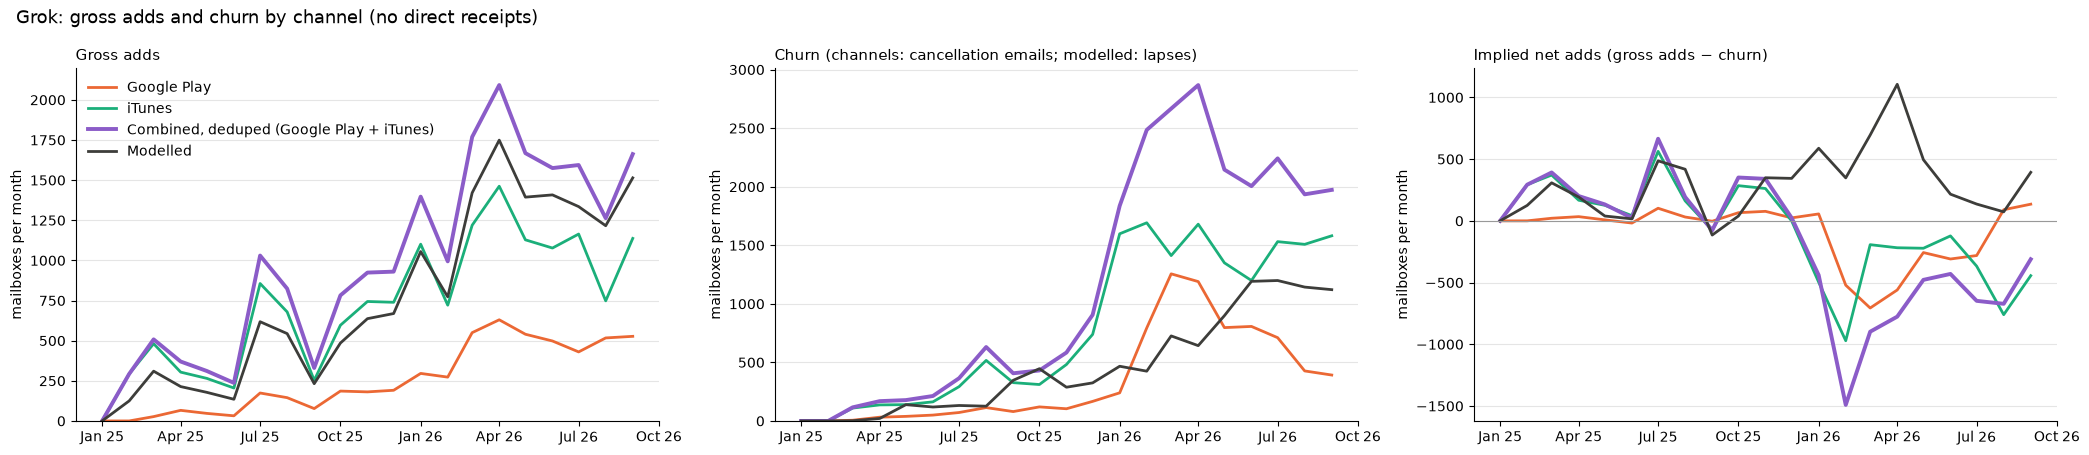

,gross_adds,churn,gross_adds_share,churn_share
Google Play,5387.00,7398.0,0.262,0.306
iTunes,15172.00,16769.0,0.738,0.694
"Combined, deduped",20553.00,24158.0,NaN,NaN
Combined / sum of those channels,1.00,1.0,NaN,NaN
Sum of channels the model reads (Google Play + iTunes),20559.00,24167.0,NaN,NaN
Modelled,16012.00,9760.0,NaN,NaN
Modelled / those channels,0.78,0.4,NaN,NaN


Correlation of monthly gross adds across channels (2025-01 to 2026-09)

,Google Play,iTunes,Combined,Modelled
Google Play,1.00,0.90,0.96,0.98
iTunes,0.90,1.00,0.99,0.95
Combined,0.96,0.99,1.00,0.99
Modelled,0.98,0.95,0.99,1.00


Correlation of monthly churn across channels (2025-01 to 2026-09)

,Google Play,iTunes,Combined,Modelled
Google Play,1.00,0.79,0.92,0.65
iTunes,0.79,1.00,0.97,0.78
Combined,0.92,0.97,1.00,0.77
Modelled,0.65,0.78,0.77,1.00


In [28]:
compare({"Google Play": gk_gp, "iTunes": gk_it}, "Grok: gross adds and churn by channel (no direct receipts)", model=model_tab("grok", exclude_plans=r"^(premium_plus|xsub)"))

**Reading it**
- **The two stores agree closely** (add correlation 0.90, churn 0.81). iTunes carries about three-quarters of both adds and churn.
- **Churn exceeds gross adds** on both stores. About 40–50% of Grok cancellations have no prior paid or confirmation email in that channel, which fits free trials being cancelled before the first charge (Grok trials are very common). The churn line therefore includes trial cancellations as well as paid churn. The early-2026 churn spike on both stores coincides with heavy trial volumes.
- **Modelled vs observed:** the modelled line excludes X Premium+ plans, to match the stores here. Modelled adds track both stores closely (0.98 Google Play, 0.95 iTunes) at about 0.8 times their sum. Modelled churn is only about 0.4 times the cancellation emails, and it doesn't show the early-2026 cancellation spike. That fits most of those cancellations being trials that never paid, which the model doesn't count as subscriptions.

## 5. Perplexity

**Merchants found:** `Perplexity AI` (4212) and `Perplexity AI Cancellation` (4213). Both direct merchants exist.

### 5a. Direct (`Perplexity AI`, `Perplexity AI Cancellation`)

In [29]:
m_dir = df.merchant_id.isin([4212, 4213])
patterns(m_dir, top=10)
sequences(m_dir, n=4, seed=2)

rows  priced_share  median_price
merchant_name              pattern                                                                                                                                          
Perplexity AI              welcome to perplexity                                                                                           66566           0.0           NaN
                           welcome to perplexity pro                                                                                       37037           0.0           NaN
Perplexity AI Cancellation perplexity pro trial has ended                                                                                  12968           0.0           NaN
                           pro subscription cancellation                                                                                    6622           0.0           NaN
                           perplexity pro plan has been canceled                                                                            4010           0.0           NaN
                           your perplexity pro subscription has been canceled                                                               3719           0.0           NaN
Perplexity AI              welcome to perplexity pro via samsung galaxy                                                                     1790           0.0           NaN
                           welcome to perplexity max                                                                                         832           0.0           NaN
                           welcome to perplexity enterprise pro                                                                              646           0.0           NaN
                           welcome to perplexity for education                                                                               428           0.0           NaN
                           welcome to perplexity's ai digest                                                                                  72           0.0           NaN
                           welcome to perplexity api organization                                                                             25           0.0           NaN
                           welcome to perplexity[external]                                                                                     1           0.0           NaN
Perplexity AI Cancellation pro subscription[caution: email from external sender. do not click or open links or attachments unless you kno      1           0.0           NaN

,mailbox_id,order_date,merchant_name,description,item_price
3768782,03afc051-ebd1-3079-84f8-6ea0a9e331ef,2025-07-17,Perplexity AI,Welcome to Perplexity Pro,NaN
3768783,03afc051-ebd1-3079-84f8-6ea0a9e331ef,2026-07-17,Perplexity AI Cancellation,Perplexity Pro trial has ended,NaN
2628621,1098b329-51fe-3b4b-8d48-562e973bc1ac,2025-03-12,Perplexity AI,Welcome to Perplexity Pro,NaN
2628622,1098b329-51fe-3b4b-8d48-562e973bc1ac,2025-03-12,Perplexity AI,Welcome to Perplexity,NaN
2628625,1098b329-51fe-3b4b-8d48-562e973bc1ac,2025-08-12,Perplexity AI Cancellation,Pro subscription Cancellation,NaN
6350748,2b517c88-6712-3fef-ac9d-381ddd028d88,2024-08-31,Perplexity AI,Welcome to Perplexity Pro,NaN
6350749,2b517c88-6712-3fef-ac9d-381ddd028d88,2024-08-31,Perplexity AI,Welcome to Perplexity,NaN
6350731,2b517c88-6712-3fef-ac9d-381ddd028d88,2025-08-31,Perplexity AI Cancellation,Perplexity Pro trial has ended,NaN
3576337,eac46c00-e2ac-3cf9-a6e9-dd96e205b2af,2025-05-04,Perplexity AI,Welcome to Perplexity Pro,NaN
3576368,eac46c00-e2ac-3cf9-a6e9-dd96e205b2af,2025-06-13,Perplexity AI Cancellation,Pro subscription Cancellation,NaN


- `Perplexity AI` sends **welcome emails only** (unpriced): `Welcome to Perplexity` (free account), `Welcome to Perplexity Pro` / `Max`, plus `… via Samsung Galaxy`, `Enterprise Pro`, `for Education` and `API organization`. There are no payment receipts. **Caveat:** many Pro welcomes are promotional free Pro (partners, trials). Earlier receipt-tracker work found only about 11% of direct Pro welcomes followed by a paid receipt, so this series measures Pro activations, not paid adds.
- `Perplexity AI Cancellation`: `Pro subscription cancellation`, `Perplexity Pro plan has been canceled`, `Your Perplexity Pro subscription has been canceled`, plus `Perplexity Pro trial has ended` (a trial expiry, not a paid cancellation).

**Filters used**
- Gross adds: `^welcome to perplexity (pro|max)$`. Free accounts, Samsung Galaxy, Enterprise, Education and API are excluded.
- Churn: `Perplexity AI Cancellation` rows, excluding `trial has ended`.

In [30]:
px_dir = build(m_dir, signup=(df.merchant_id == 4212) & has(r"^welcome to perplexity (pro|max)$"), pay=None,
               cancel=(df.merchant_id == 4213) & ~has(r"trial has ended"))
show(px_dir, "Perplexity direct: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Perplexity direct: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,861,887,617,1151,691,905,8752,2058,4012,3594,1457,2799,860,1071,1380,1359,655,557,206,185,211,131
churn,781,503,553,422,903,300,315,349,304,378,1228,413,404,464,516,656,794,751,692,614,1720,1002


### 5b. Google Play

In [31]:
m_gp = (df.channel == "gp") & has(r"perplexity")
patterns(m_gp, top=8)
sequences(m_gp, n=3, seed=2)

rows  priced_share  median_price
merchant_name            pattern                                                                                                                                         
Google Play              perplexity pro (perplexity - ask anything) auto-renewing subscription                                           3740           1.0         19.99
                         # credits (perplexity - ask anything)                                                                            565           1.0         10.00
Google Play Cancellation perplexity - ask anything subscription from perplexity ai inc on google play has been canceled.                  174           0.0           NaN
                         your perplexity - ask anything subscription from perplexity ai inc on google play will be canceled on jan #, #   122           0.0           NaN
                         your perplexity - ask anything subscription from perplexity ai inc on google play will be canceled on apr #, #   115           0.0           NaN
                         your perplexity - ask anything subscription from perplexity ai inc on google play will be canceled on may #, #    85           0.0           NaN
                         your perplexity - ask anything subscription from perplexity ai inc on google play will be canceled on aug #, #    66           0.0           NaN
                         your perplexity - ask anything subscription from perplexity ai inc on google play will be canceled on jun #, #    65           0.0           NaN
                         your perplexity - ask anything subscription from perplexity ai inc on google play will be canceled on mar #, #    62           0.0           NaN
                         your perplexity - ask anything subscription from perplexity ai inc on google play will be canceled on oct #, #    58           0.0           NaN
Google Play              your trial will end on mar #, #. you will be automatically charged the subscription cost (currently $#.#/month    54           0.0          0.00
                         perplexity max (perplexity - ask anything) auto-renewing subscription                                             53           1.0        199.99
                         your trial will end on feb #, #. you will be automatically charged the subscription cost (currently $#.#/month    31           0.0          0.00
                         perplexity max (perplexity - ask anything)                                                                        15           1.0        199.99
                         your trial will end on apr #, #. you will be automatically charged the subscription cost (currently $#.#/year)     3           0.0          0.00
                         perplexity pro (perplexity - ask anything)                                                                         2           1.0        109.99

,mailbox_id,order_date,merchant_name,description,item_price
1921906,e1eb050f-f007-310d-a02c-c0ae0a7b7d1f,2026-03-19,Google Play,Perplexity Pro (Perplexity - Ask Anything) Auto-renewing subscription,19.99
1921879,e1eb050f-f007-310d-a02c-c0ae0a7b7d1f,2026-04-19,Google Play,Perplexity Pro (Perplexity - Ask Anything) Auto-renewing subscription,19.99
1921866,e1eb050f-f007-310d-a02c-c0ae0a7b7d1f,2026-04-28,Google Play Cancellation,Your Perplexity - Ask Anything subscription from Perplexity AI Inc on Google Play will be canceled on May ...,NaN
1921909,e1eb050f-f007-310d-a02c-c0ae0a7b7d1f,2026-05-12,Google Play Cancellation,Perplexity - Ask Anything (Perplexity Pro) subscription will end on May 19,NaN
11855574,e2bc4157-97c1-3f17-a4db-1db24a1ab5de,2026-02-06,Google Play,Perplexity Pro (Perplexity - Ask Anything) Auto-renewing subscription,19.99
11855564,e2bc4157-97c1-3f17-a4db-1db24a1ab5de,2026-03-12,Google Play Cancellation,Perplexity - Ask Anything subscription from Perplexity AI Inc on Google Play has been canceled.,NaN
4729236,fd6714c7-14cc-3903-9a42-4875434261bb,2025-10-20,Google Play,Perplexity Pro (Perplexity - Ask Anything) Auto-renewing subscription,19.99
4729237,fd6714c7-14cc-3903-9a42-4875434261bb,2025-11-20,Google Play,Perplexity Pro (Perplexity - Ask Anything) Auto-renewing subscription,19.99
4729244,fd6714c7-14cc-3903-9a42-4875434261bb,2025-12-20,Google Play,Perplexity Pro (Perplexity - Ask Anything) Auto-renewing subscription,19.99
4729228,fd6714c7-14cc-3903-9a42-4875434261bb,2025-12-28,Google Play Cancellation,Your Perplexity - Ask Anything subscription from Perplexity AI Inc on Google Play will be canceled on Jan ...,NaN


The structure matches ChatGPT on Google Play: `Perplexity Pro (Perplexity - Ask Anything) Auto-renewing subscription` (and Max) is priced at sign-up and each renewal, and `# Credits` are one-off. Cancellations read `Your Perplexity - Ask Anything subscription from Perplexity AI Inc … will be canceled on…`, `… has been canceled.` and `… (Perplexity Pro) subscription will end on…`.

**Filters used**
- Gross adds: `Google Play` rows matching `perplexity (pro|max) \(perplexity.*auto-renewing subscription`.
- Churn: `Google Play Cancellation` rows mentioning `perplexity`.

In [32]:
px_gp = build(m_gp, signup=None, pay=GP_PAY & has(r"perplexity (pro|max) \(perplexity.*auto-renewing subscription"),
              cancel=(df.merchant_id == 3452))
show(px_gp, "Perplexity Google Play: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Perplexity Google Play: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,39,47,63,31,30,42,33,28,48,56,40,43,38,46,122,88,72,47,44,41,24,23
churn,132,62,84,48,32,31,34,24,33,36,21,35,26,31,63,64,66,32,57,50,41,20


### 5c. iTunes (App Store)

In [33]:
m_it = (df.channel == "itunes") & has(r"perplexity (pro|max)")
patterns(m_it, top=12)
sequences(m_it, n=3, seed=2)

rows  priced_share  median_price
merchant_name       pattern                                                                                                                                          
iTunes              perplexity - ai search & chat : perplexity pro (monthly)                                                        12130           1.0          20.0
                    perplexity - ask anything : perplexity pro (monthly)                                                             5449           1.0          20.0
iTunes Cancellation perplexity - ai search & chat perplexity pro (# month)                                                           3012           1.0          20.0
iTunes              perplexity - ai search & chat perplexity pro $#.# /month                                                         2894           0.0           NaN
                    perplexity: ask anything : perplexity pro for mac (monthly)                                                      1122           1.0          20.0
                    perplexity - ask anything perplexity pro usd #.# /month                                                          1059           0.0           NaN
iTunes Cancellation perplexity - ask anything perplexity pro (# month)                                                                974           1.0          20.0
iTunes              perplexity - ai search & chat : perplexity pro (annual)                                                           629           1.0         200.0
                    perplexity - ai search & chat : perplexity max (monthly)                                                          546           1.0         200.0
                    perplexity - ai search & chat perplexity pro $#.# /year                                                           494           0.0           NaN
iTunes Cancellation perplexity - ai search & chat perplexity pro (# year)                                                             307           1.0         200.0
iTunes              perplexity - ask anything perplexity pro $#.# /month                                                              191           0.0           NaN
                    perplexity - ask anything : perplexity pro (annual)                                                               173           1.0         200.0
iTunes Cancellation perplexity: ask anything perplexity pro for mac (# month)                                                         168           1.0          20.0
iTunes              perplexity - ask anything perplexity pro usd #.# /year                                                            160           0.0           NaN
                    perplexity - ai search & chat perplexity pro # week, starting may #, # free trial. price: #.# /month, starting    141           0.0           NaN
iTunes Cancellation perplexity - ai search & chat perplexity max (# month)                                                             94           1.0         200.0
                    perplexity - ask anything perplexity pro (# year)                                                                  42           1.0         200.0
                    perplexity - ask anything perplexity max (# month)                                                                 12           1.0         200.0
                    perplexity: ask anything perplexity pro for mac (# year)                                                           12           1.0         200.0
                    comet - ai browser & assistant perplexity pro (# month)                                                            11           1.0          20.0
                    perplexity: ask anything perplexity max (# month)                                                                   4           1.0         200.0

,mailbox_id,order_date,merchant_name,description,item_price
11460056,32bf748f-d2b4-3f31-8704-0dc047686b34,2024-12-01,iTunes,Perplexity: Ask Anything Perplexity Pro for Mac USD 20.00 /month,NaN
11460038,32bf748f-d2b4-3f31-8704-0dc047686b34,2024-12-01,iTunes,Perplexity: Ask Anything : Perplexity Pro for Mac (Monthly),20.0
11460025,32bf748f-d2b4-3f31-8704-0dc047686b34,2025-01-02,iTunes,Perplexity: Ask Anything : Perplexity Pro for Mac (Monthly),20.0
11460055,32bf748f-d2b4-3f31-8704-0dc047686b34,2025-02-01,iTunes,Perplexity: Ask Anything : Perplexity Pro for Mac (Monthly),20.0
11460060,32bf748f-d2b4-3f31-8704-0dc047686b34,2025-03-03,iTunes,Perplexity: Ask Anything : Perplexity Pro for Mac (Monthly),20.0
11460015,32bf748f-d2b4-3f31-8704-0dc047686b34,2025-04-03,iTunes,Perplexity: Ask Anything : Perplexity Pro for Mac (Monthly),20.0
11460052,32bf748f-d2b4-3f31-8704-0dc047686b34,2025-05-05,iTunes,Perplexity: Ask Anything Perplexity Pro for Mac USD 20.00 /month,NaN
11460051,32bf748f-d2b4-3f31-8704-0dc047686b34,2025-05-09,iTunes,Perplexity: Ask Anything : Perplexity Pro for Mac (Monthly),20.0
11460034,32bf748f-d2b4-3f31-8704-0dc047686b34,2025-06-08,iTunes,Perplexity: Ask Anything : Perplexity Pro for Mac (Monthly),20.0
11460018,32bf748f-d2b4-3f31-8704-0dc047686b34,2025-07-05,iTunes,Perplexity: Ask Anything : Perplexity Pro for Mac (Monthly),20.0


The structure matches the other apps. There is a confirmation `Perplexity - AI Search & Chat Perplexity Pro $20.00 /month` and a priced receipt per sign-up and renewal (`… : Perplexity Pro (Monthly)`, `(Annual)`). The app has two names (`Perplexity - Ask Anything`, then `Perplexity - AI Search & Chat`), and there is a Mac app (`Perplexity Pro for Mac`) and Comet (`Comet - AI Browser & Assistant Perplexity Pro`). Cancellations read `… Perplexity Pro (1 month)`. Credits are excluded by the plan filter.

**Filters used**
- Gross adds: the first in a series of confirmations or priced subscription receipts mentioning `perplexity (pro|max)`. Annual plans use the 400-day window.
- Churn: `iTunes Cancellation` rows mentioning `perplexity (pro|max)`.

In [34]:
px_it = build(m_it, signup=(df.merchant_id == 5) & IT_SIGNUP, pay=(df.merchant_id == 5) & IT_PAY,
              cancel=(df.merchant_id == 20122), annual=IT_ANNUAL)
show(px_it, "Perplexity iTunes: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Perplexity iTunes: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,204,192,240,176,184,233,207,193,200,271,225,233,339,357,477,605,599,488,356,305,285,173
churn,171,127,97,95,85,102,114,125,142,139,172,114,195,210,198,358,484,414,427,340,292,192


### 5d. Perplexity: channel comparison

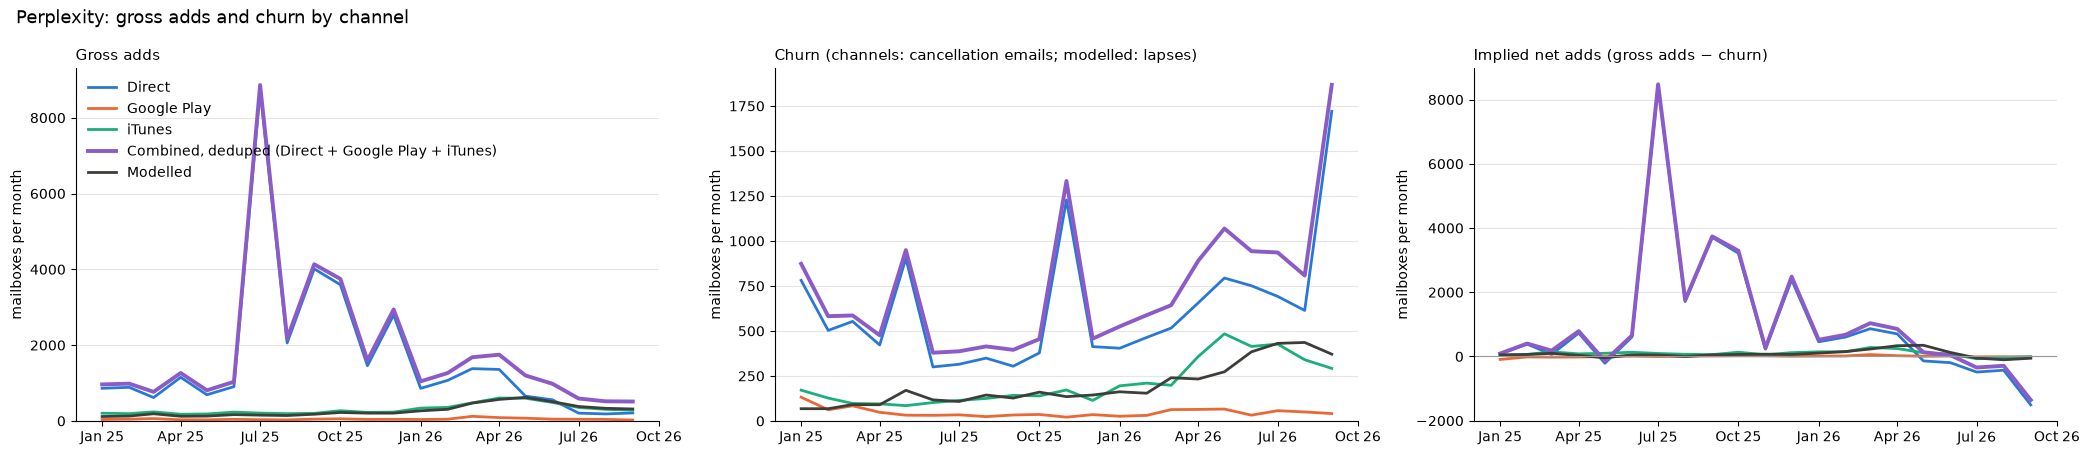

,gross_adds,churn,gross_adds_share,churn_share
Direct,34268.000,13060.000,0.823,0.707
Google Play,1022.000,1002.000,0.025,0.054
iTunes,6369.000,4401.000,0.153,0.238
"Combined, deduped",38816.000,15555.000,NaN,NaN
Combined / sum of those channels,0.932,0.842,NaN,NaN
Sum of channels the model reads (Google Play + iTunes),7391.000,5403.000,NaN,NaN
Modelled,5733.000,4106.000,NaN,NaN
Modelled / those channels,0.780,0.760,NaN,NaN


Correlation of monthly gross adds across channels (2025-01 to 2026-09)

,Direct,Google Play,iTunes,Combined,Modelled
Direct,1.00,-0.09,-0.27,1.00,-0.29
Google Play,-0.09,1.00,0.68,-0.06,0.63
iTunes,-0.27,0.68,1.00,-0.21,0.98
Combined,1.00,-0.06,-0.21,1.00,-0.23
Modelled,-0.29,0.63,0.98,-0.23,1.00


Correlation of monthly churn across channels (2025-01 to 2026-09)

,Direct,Google Play,iTunes,Combined,Modelled
Direct,1.00,0.09,0.36,0.98,0.43
Google Play,0.09,1.00,0.14,0.11,-0.10
iTunes,0.36,0.14,1.00,0.52,0.82
Combined,0.98,0.11,0.52,1.00,0.54
Modelled,0.43,-0.10,0.82,0.54,1.00


In [35]:
compare({"Direct": px_dir, "Google Play": px_gp, "iTunes": px_it}, "Perplexity: gross adds and churn by channel", model=model_tab("perplexity"), model_covers=["Google Play", "iTunes"])

**Reading it**
- **Direct is not comparable with the stores.** Direct "adds" are Pro welcome emails, which are dominated by promotional free Pro activations: the July 2025 spike of about 8.8k and the elevated autumn 2025 months look promotional. Direct does not correlate with the stores (−0.27 against iTunes for adds). Direct churn also changes wording twice (January 2026, July 2026), and the September 2026 spike falls in the new `Your Perplexity Pro subscription has been canceled` format, consistent with a promotional cohort expiring.
- **iTunes and Google Play agree reasonably on adds** (0.68), and iTunes is about 6 times Google Play. Both are small.
- **Modelled vs observed:** the model reads Google Play and iTunes and follows iTunes almost exactly for adds (0.98) and churn (0.82), at about 0.8 times the two stores combined. Direct Perplexity (welcome emails) is not in the model.

## 6. Muse (Meta)

**Merchants found: no `Muse` merchant and no Muse cancellation merchant.** Muse rows sit under `Meta` (3848) and come only from the descriptions. Meta carries:
- `Welcome to Muse Code Everyday / High / Power / Maximum usage`: priced ($5 / $15 / $50 / $200) sign-up emails for **Muse Code** plans, since September 2026. These are the only direct subscription-like emails, so they are used as the direct series.
- `Muse Spark / Wonder / Image … tokens`: API usage, excluded.
- `Age confirmation on Muse` and `Welcome to the confidential early testing program for Muse`: not subscriptions, excluded.

**No direct receipts were found for the consumer Power / Maximum plans bought on the web**, and Meta has no cancellation sender. The direct line is therefore Muse Code sign-ups only and is **not comparable** to the store lines. Muse launched on 2026-09-07, so every series starts then.

### 6a. Direct (`Meta`)

In [36]:
m_dir = (df.merchant_id == 3848)
patterns(m_dir & has(r"\bmuse\b"), top=15)
mu_dir = build(m_dir, signup=has(r"^welcome to muse code .*usage$"), pay=None, cancel=pd.Series(False, index=df.index))
show(mu_dir, "Muse direct (Muse Code welcome emails): monthly gross adds")

rows  priced_share  median_price
merchant_name pattern                                                                                                              
Meta          age confirmation on muse                                                              345          0.00           NaN
              muse spark #.# - response tokens                                                       86          0.94          0.76
              muse spark #.# - uncached request tokens                                               73          0.92          1.46
              muse spark #.# - cached request tokens                                                 62          0.89          1.21
              muse spark #.# contributor - response tokens                                           61          0.87          0.33
              muse spark #.# contributor - uncached request tokens                                   61          0.97          2.36
              muse spark #.# contributor - cached request tokens                                     59          0.81          0.26
              welcome to the confidential early testing program for muse, your #/# personal agent    40          0.00           NaN
              welcome to muse code power usage                                                       35          1.00         50.00
              welcome to muse code everyday usage                                                    34          1.00          5.00
              welcome to muse code high usage                                                        29          1.00         15.00
              synth riders: muse - "starlight" + experience™                                         22          1.00          2.99
              synth riders: muse - "uprising"                                                        16          1.00          1.99
              muse wonder #.# - response tokens                                                      13          1.00          3.98
              muse wonder #.# - uncached request tokens                                              13          1.00          6.14

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Muse direct (Muse Code welcome emails): monthly gross adds** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,31,46
churn,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 6b. Google Play

In [37]:
m_gp = (df.channel == "gp") & has(r"muse from meta")
patterns(m_gp, top=8)
sequences(m_gp, n=3, seed=1, since="2026-09-01")

rows  priced_share  median_price
merchant_name            pattern                                                                                                                         
Google Play              power plan (muse from meta) auto-renewing subscription                                           166           1.0         20.00
Google Play Cancellation your muse from meta subscription from facebook inc on google play will be canceled on oct #, #     7           0.0           NaN
                         your muse from meta subscription from facebook inc on google play will be canceled on nov #, #     6           0.0           NaN
Google Play              maximum plan (muse from meta)                                                                      6           1.0         59.31
Google Play Cancellation muse from meta (power plan) subscription will end on oct #                                         3           0.0           NaN
Google Play              maximum plan (muse from meta) auto-renewing subscription                                           1           1.0        100.00

,mailbox_id,order_date,merchant_name,description,item_price
3653390,2d0706b6-7ac5-3f2c-9acf-00ee3b5063d7,2026-10-08,Google Play,Power Plan (Muse from Meta) Auto-renewing subscription,20.0
3653404,2d0706b6-7ac5-3f2c-9acf-00ee3b5063d7,2026-10-09,Google Play Cancellation,"Your Muse from Meta subscription from Facebook Inc on Google Play will be canceled on Nov 8, 2026",NaN
2877564,3a83a963-2ce3-3c5f-ab7d-48572ffb1cf3,2026-09-24,Google Play,Power Plan (Muse from Meta) Auto-renewing subscription,20.0
2877583,3a83a963-2ce3-3c5f-ab7d-48572ffb1cf3,2026-09-24,Google Play Cancellation,"Your Muse from Meta subscription from Facebook Inc on Google Play will be canceled on Oct 24, 2026",NaN
2877575,3a83a963-2ce3-3c5f-ab7d-48572ffb1cf3,2026-10-17,Google Play Cancellation,Muse from Meta (Power Plan) subscription will end on Oct 24,NaN
5448644,542e6a00-909a-3129-8116-9ed4a94ccaaf,2026-10-12,Google Play,Power Plan (Muse from Meta) Auto-renewing subscription,20.0
5448646,542e6a00-909a-3129-8116-9ed4a94ccaaf,2026-10-12,Google Play Cancellation,"Your Muse from Meta subscription from Facebook Inc on Google Play will be canceled on Nov 12, 2026",NaN


`Power Plan (Muse from Meta) Auto-renewing subscription` ($20) and `Maximum Plan (Muse from Meta) …` ($100) are priced and sent at sign-up and each renewal. Cancellations read `Your Muse from Meta subscription from Facebook Inc on Google Play will be canceled on…` and `Muse from Meta (Power Plan) subscription will end on…`. Volumes are small (under 200 rows).

**Filters used**
- Gross adds: `Google Play` rows matching `\(muse from meta\) auto-renewing subscription`.
- Churn: `Google Play Cancellation` rows mentioning `muse from meta`.

In [38]:
mu_gp = build(m_gp, signup=None, pay=GP_PAY & has(r"\(muse from meta\) auto-renewing subscription"),
              cancel=(df.merchant_id == 3452))
show(mu_gp, "Muse Google Play: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Muse Google Play: monthly gross adds and churn** (month 2026-10 is partial)

month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
gross_adds,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,57,104
churn,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6,7


### 6c. iTunes (App Store)

In [39]:
m_it = (df.channel == "itunes") & (has(r"^muse from meta") | df.d.isin(["power plan", "maximum plan"]) | has(r"^(power|maximum) plan : (power|maximum) plan"))
patterns(m_it, top=10)
sequences(m_it, n=3, seed=1, since="2026-09-01")

rows  priced_share  median_price
merchant_name       pattern                                                                  
iTunes              muse from meta power plan $#.# /month     404           0.0           NaN
                    power plan                                295           1.0          20.0
iTunes Cancellation muse from meta power plan (# month)        31           1.0          20.0
iTunes              maximum plan                               20           1.0         100.0
                    power plan : power plan (monthly)          13           1.0          20.0
                    muse from meta maximum plan $#.# /month    11           0.0           NaN
iTunes Cancellation muse from meta maximum plan (# month)       3           1.0         100.0

,mailbox_id,order_date,merchant_name,description,item_price
9907222,32523407-b242-3db7-9779-07fd690918fd,2026-09-11,iTunes,Muse from Meta Power Plan $20.00 /month,NaN
9907224,32523407-b242-3db7-9779-07fd690918fd,2026-09-11,iTunes,Power Plan,20.0
9907223,32523407-b242-3db7-9779-07fd690918fd,2026-09-27,iTunes Cancellation,Muse from Meta Power Plan (1 month),20.0
2958685,8c61dc6f-2bdd-368b-a192-c786843e22f1,2026-10-03,iTunes,Muse from Meta Power Plan $20.00 /month,NaN
2958675,8c61dc6f-2bdd-368b-a192-c786843e22f1,2026-10-05,iTunes,Power Plan,20.0
2958679,8c61dc6f-2bdd-368b-a192-c786843e22f1,2026-10-20,iTunes Cancellation,Muse from Meta Power Plan (1 month),20.0
4209713,b06a45ae-f5b1-3018-95b7-346dc7d598f1,2026-09-24,iTunes,Muse from Meta Power Plan $20.00 /month,NaN
4209717,b06a45ae-f5b1-3018-95b7-346dc7d598f1,2026-09-28,iTunes,Power Plan,20.0
4209715,b06a45ae-f5b1-3018-95b7-346dc7d598f1,2026-10-09,iTunes Cancellation,Muse from Meta Power Plan (1 month),20.0


Apple's Muse receipts **don't name the app on the priced row**. At sign-up there is an unpriced confirmation `Muse from Meta Power Plan $20.00 /month` and a priced receipt that reads only `Power Plan` / `Maximum Plan`. Renewals read `Power Plan : Power Plan (Monthly)`, with the plan used as the app name. Cancellations read `Muse from Meta Power Plan (1 month)`. Rows from unrelated apps (`Power Planner`, `AI-Story … Unlimited Power Plan`) are excluded by requiring the exact `Power Plan` / `Maximum Plan` description or the `Muse from Meta` prefix.

**Filters used**
- Gross adds: the first in a series of `Muse from Meta … /month` confirmations, bare priced `Power Plan` / `Maximum Plan`, or `Power|Maximum Plan : … (Monthly)`.
- Churn: `iTunes Cancellation` rows starting `muse from meta`.

In [40]:
mu_it = build(m_it, signup=(df.merchant_id == 5) & IT_SIGNUP, pay=(df.merchant_id == 5) & df.priced,
              cancel=(df.merchant_id == 20122))
mu_tabs = {k: v[v.index >= "2026-09"] for k, v in {"Direct": mu_dir, "Google Play": mu_gp, "iTunes": mu_it}.items()}
show(mu_tabs["iTunes"], "Muse iTunes: monthly gross adds and churn")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\826771284.py:51: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  j = pd.merge_asof(churn.sort_values("dt"), sig, left_on="dt", right_on="sdt", by="mailbox_id", direction="backward", tolerance=pd.Timedelta(days=400))


**Muse iTunes: monthly gross adds and churn** (month 2026-10 is partial)

month,2026-09,2026-10
gross_adds,146,274
churn,3,31


### 6d. Muse: channel comparison

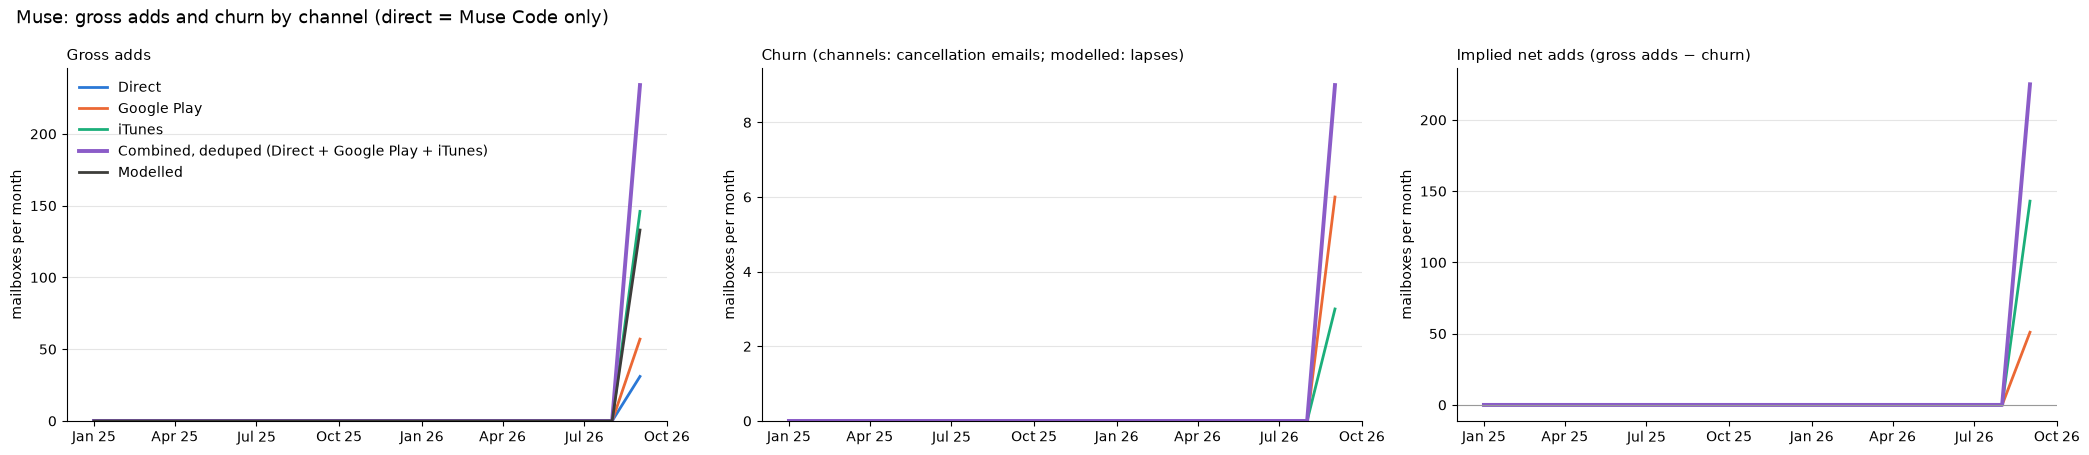

,gross_adds,churn,gross_adds_share,churn_share
Direct,31.00,0.0,0.132,0.000
Google Play,57.00,6.0,0.244,0.667
iTunes,146.00,3.0,0.624,0.333
"Combined, deduped",234.00,9.0,NaN,NaN
Combined / sum of those channels,1.00,1.0,NaN,NaN
Sum of channels the model reads (Google Play + iTunes),203.00,9.0,NaN,NaN
Modelled,133.00,0.0,NaN,NaN
Modelled / those channels,0.66,0.0,NaN,NaN


Direct       Google Play           iTunes      
        gross_adds churn  gross_adds churn gross_adds churn
month                                                      
2026-09         31     0          57     6        146     3
2026-10         46     0         104     7        274    31

In [41]:
compare({"Direct": mu_dir, "Google Play": mu_gp, "iTunes": mu_it}, "Muse: gross adds and churn by channel (direct = Muse Code only)", model=model_tab("muse"), model_covers=["Google Play", "iTunes"])
display(pd.concat(mu_tabs, axis=1))

**Reading it**
- Muse launched on 2026-09-07, so there is only one complete month (September 2026) and a partial October. Correlations aren't meaningful yet.
- **iTunes captures the most Muse adds**, at about 2.5 times Google Play in both months. The direct line is Muse Code sign-ups only, because consumer web purchases of Power or Maximum send no receipt that NIQ captures, so it is not comparable.
- Churn is very small so far (single and double digits).
- **Modelled vs observed:** modelled adds for September 2026 (133) are about 0.66 times Google Play plus iTunes (203). Modelled churn is still zero, because the first cohorts haven't passed their lapse window.

## 7. Summary across providers

Totals of gross adds and churn, complete months from 2025-01 (and the last three complete months). `churn_no_prior_add_share` is the share of cancellations whose mailbox had no sign-up or paid email in that channel in the prior 400 days. That covers trials cancelled before any payment and subscriptions whose receipts the panel missed. A high share means the churn line includes people who never show up as adds. A channel missing from a provider has no usable receipts.

In [42]:
ALL = {"ChatGPT": {"Direct": cg_dir, "Google Play": cg_gp, "iTunes": cg_it},
       "Claude": {"Direct": cl_dir, "Google Play": cl_gp, "iTunes": cl_it},
       "Gemini": {"Direct": gm_dir, "Direct-only": gm_dir_only, "Google Play": gm_gp, "iTunes": gm_it},
       "Grok": {"Google Play": gk_gp, "iTunes": gk_it},
       "Perplexity": {"Direct": px_dir, "Google Play": px_gp, "iTunes": px_it},
       "Muse": {"Direct": mu_dir, "Google Play": mu_gp, "iTunes": mu_it}}
rows = []
MODELS = {"ChatGPT": "chatgpt", "Claude": "claude", "Gemini": "gemini", "Grok": "grok", "Perplexity": "perplexity", "Muse": "muse"}
for p, tabs in ALL.items():
    tabs = dict(tabs, Combined=combined({k: v for k, v in tabs.items() if k != "Direct-only"}), Modelled=model_tab(MODELS[p], exclude_plans=r"^(premium_plus|xsub)" if p == "Grok" else None))
    for ch, t in tabs.items():
        t = t[t.index >= "2025-01"]
        t = t[t.index <= LAST_FULL]
        rows.append(dict(provider=p, channel=ch, gross_adds=t.gross_adds.sum(), churn=t.churn.sum(),
                         adds_last3m=t.gross_adds.tail(3).sum(), churn_last3m=t.churn.tail(3).sum(),
                         churn_no_prior_add_share=round(t.attrs.get("churn_no_prior_add", np.nan), 3)))
summ = pd.DataFrame(rows).set_index(["provider", "channel"])
summ

gross_adds   churn  adds_last3m  churn_last3m  churn_no_prior_add_share
provider   channel                                                                             
ChatGPT    Direct           161424  148739        32070         22978                     0.481
           Google Play       47108   30076         8532          4908                     0.108
           iTunes           211455  117224        18600         14533                     0.017
           Combined         416400  272645        58368         37638                       NaN
           Modelled         203320  133988        27803         24372                       NaN
Claude     Direct           114006   38830        23113         12294                     0.017
           Google Play        4818    2999         1176          1033                     0.174
           iTunes            23650    9774         5507          3853                     0.014
           Combined         140980   51311        29442         17084                       NaN
           Modelled         109952   51720        25976         19273                       NaN
Gemini     Direct           142564   78935        26869         10950                     0.255
           Direct-only       99815   51024        10569          4669                     0.271
           Google Play       66927   35677        18793          7992                     0.328
           iTunes             6682    4496         1496           650                     0.470
           Combined         170676   91789        36354         16054                       NaN
           Modelled         103093   41247        25376         12684                       NaN
Grok       Google Play        5387    7398         1474          1530                     0.512
           iTunes            15172   16769         3049          4620                     0.411
           Combined          20553   24158         4519          6150                       NaN
           Modelled          16012    9760         4065          3463                       NaN
Perplexity Direct            34268   13060          602          3026                     0.221
           Google Play        1022    1002          109           148                     0.270
           iTunes             6369    4401          946          1059                     0.162
           Combined          38816   15555         1622          3611                       NaN
           Modelled           5733    4106         1030          1238                       NaN
Muse       Direct               31       0           31             0                       NaN
           Google Play          57       6           57             6                     0.000
           iTunes              146       3          146             3                     0.000
           Combined            234       9          234             9                       NaN
           Modelled            133       0          133             0                       NaN

### Export for the app

Monthly gross adds, churn and net adds (gross adds minus churn) per provider and channel, plus the deduped combined series, for complete months from 2025-01. The combined series uses the agreed channel set: direct + Google Play + iTunes, except Perplexity and Grok (Google Play + iTunes only). Perplexity direct is mostly free promotional sign-ups, and Grok has no direct sender. Written to `../.cache/channel_cmp/channel_flows.parquet` and merged into the app by `app/channel_flows.py`.

In [43]:
COMBINE = {"ChatGPT": ["Direct", "Google Play", "iTunes"], "Claude": ["Direct", "Google Play", "iTunes"],
           "Gemini": ["Direct", "Google Play", "iTunes"], "Grok": ["Google Play", "iTunes"],
           "Perplexity": ["Google Play", "iTunes"], "Muse": ["Direct", "Google Play", "iTunes"]}
out = []
for p, tabs in ALL.items():
    use = {k: v for k, v in tabs.items() if k in ("Direct", "Google Play", "iTunes")}
    for ch, t in dict(use, Combined=combined({k: use[k] for k in COMBINE[p]})).items():
        t = t[(t.index >= "2025-01") & (t.index <= LAST_FULL)]
        out.append(pd.DataFrame({"PROVIDER": p.lower(), "CHANNEL": ch, "MONTH": t.index.astype(str), "GROSS_ADDS": t.gross_adds.values,
                                 "CHURN": t.churn.values, "IN_COMBINED": ch in COMBINE[p] or ch == "Combined"}))
flows = pd.concat(out, ignore_index=True)
flows["NET_ADDS"] = flows.GROSS_ADDS - flows.CHURN
flows.to_parquet("../.cache/channel_cmp/channel_flows.parquet", index=False)
flows[flows.CHANNEL == "Combined"].pivot(index="MONTH", columns="PROVIDER", values="NET_ADDS").tail(6)

PROVIDER,chatgpt,claude,gemini,grok,muse,perplexity
MONTH,,,,,,
2026-04,1738,16810,2078,-776,0,271
2026-05,1563,10343,3279,-478,0,121
2026-06,3011,7592,6935,-430,0,88
2026-07,4965,5273,6207,-648,0,-84
2026-08,7167,3653,6964,-672,0,-44
2026-09,8598,3432,7129,-311,225,-24


### Plan-level split (combined series)

Each email is labelled with the plan it names (tier only; monthly and annual are pooled). Claude direct payments are labelled by price: $20 is Pro, $100 or $200 is Max.
- **Gross adds** take the plan of the first email in the series that names one (some iTunes confirmations and Google Play cancellations don't).
- **Plan switches:** within a series, a change in the named plan (e.g. Plus receipts, then Pro receipts) is a switch. It moves one subscriber from the old plan to the new one, so it is not churn plus a new add. The same switch seen in two channels within 45 days counts once.
- **Churn** takes the mailbox's plan at the time: the last plan named on a sign-up or paid email in any combined channel in the 400 days before the cancellation. Failing that, it uses the plan the cancellation names, else `Unspecified`.
- **Plan net adds** = gross adds + switches in − churn − switches out. Switches net to zero across plans, so plan net adds sum to the provider's net adds. Small differences remain from counting distinct mailboxes per month.

Plan labels:

| Provider | Plans |
|---|---|
| ChatGPT | Plus, Go, Pro |
| Claude | Pro, Max |
| Gemini | AI Plus, AI Pro (incl. AI Premium), AI Ultra |
| Grok | SuperGrok, Lite, Heavy |
| Perplexity | Pro, Max |
| Muse | Power, Maximum, Muse Code (direct) |

In [44]:
def first_match(rules):
    '''Plan label per row: the first (plan, regex) whose regex matches the description, else None.'''
    out = pd.Series(None, index=df.index, dtype=object)
    for plan, rx in rules:
        out = out.where(out.notna(), pd.Series(np.where(has(rx), plan, None), index=df.index))
    return out

claude_pay = pd.Series(np.select([(df.merchant_id == 20127) & (df.d == "payment") & (df.item_price == 20),
                                  (df.merchant_id == 20127) & (df.d == "payment") & df.item_price.isin([100, 200])], ["Pro", "Max"], None), index=df.index)
muse_code = pd.Series(np.where(df.merchant_id == 3848, "Muse Code", None), index=df.index)
PLANS = {
    "ChatGPT": first_match([("Pro", r"\bpro\b"), ("Plus", r"\bplus\b"), ("Go", r"\bgo\b")]),
    "Claude": claude_pay.where(claude_pay.notna(), first_match([("Max", r"\bmax\b"), ("Pro", r"\bpro\b")])),
    "Gemini": first_match([("AI Ultra", r"ai ultra"), ("AI Plus", r"ai plus"), ("AI Pro", r"ai pro\b|ai premium")]),
    "Grok": first_match([("Heavy", r"heavy"), ("Lite", r"lite"), ("SuperGrok", r"super ?grok")]),
    "Perplexity": first_match([("Max", r"\bmax\b"), ("Pro", r"\bpro\b")]),
    "Muse": muse_code.where(muse_code.notna(), first_match([("Maximum", r"maximum"), ("Power", r"power")])),
}

def dedupe(ev, key=None):
    '''Drop an event within DEDUP_DAYS after one for the same mailbox (and key) in a different channel.'''
    by = ["mailbox_id"] + ([key] if key else [])
    ev = ev.sort_values(by + ["dt"]).reset_index(drop=True)
    same = ev[by].eq(ev[by].shift()).all(axis=1)
    return ev[~(same & ev.ch.ne(ev.ch.shift()) & ((ev.dt - ev.dt.shift()).dt.days <= DEDUP_DAYS))]

def plan_flows(tabs, lab):
    adds, churn, sigs, sw = [], [], [], []
    for ch, t in tabs.items():
        a, c, s = EVENTS[id(t)]
        s = s.assign(ch=ch, plan=lab.reindex(s.row).values, is_add=s.row.isin(set(a.row)))
        s = s.sort_values(["mailbox_id", "dt", "is_add"], ascending=[True, True, False]).reset_index(drop=True)
        s["series"] = (s.is_add | s.mailbox_id.ne(s.mailbox_id.shift())).cumsum()
        g = s.groupby("series").plan
        s["series_plan"] = g.ffill().where(lambda x: x.notna(), s.groupby("series").plan.bfill())
        k = s[s.plan.notna()].copy()
        k["prev"] = k.groupby("series").plan.shift()
        sw.append(k[k.prev.notna() & (k.prev != k.plan)][["mailbox_id", "dt", "ch", "prev", "plan"]])
        adds.append(s[s.is_add][["mailbox_id", "dt", "ch", "series_plan"]].rename(columns={"series_plan": "plan"}))
        churn.append(c.assign(ch=ch, own=lab.reindex(c.row).values))
        sigs.append(k[["mailbox_id", "dt", "plan"]])
    adds = dedupe(pd.concat(adds)); churn = dedupe(pd.concat(churn))
    sw = pd.concat(sw); sw["pair"] = sw.prev + ">" + sw.plan; sw = dedupe(sw, key="pair")
    kk = pd.concat(sigs).sort_values("dt")
    churn = pd.merge_asof(churn.sort_values("dt"), kk.rename(columns={"dt": "kdt"}), left_on="dt", right_on="kdt", by="mailbox_id",
                          direction="backward", tolerance=pd.Timedelta(days=400))
    churn["plan"] = churn.plan.fillna(churn.own).fillna("Unspecified")
    adds["plan"] = adds.plan.fillna("Unspecified")
    m = lambda e: e.assign(MONTH=e.dt.dt.to_period("M"))
    cnt = lambda e, by, name: m(e).groupby([by, "MONTH"]).mailbox_id.nunique().rename(name)
    t = pd.concat([cnt(adds, "plan", "GROSS_ADDS"), cnt(churn, "plan", "CHURN"),
                   cnt(sw.rename(columns={"plan": "to"}).assign(plan=lambda x: x.to), "plan", "SWITCH_IN"),
                   cnt(sw.assign(plan=sw.prev), "plan", "SWITCH_OUT")], axis=1).fillna(0).astype(int).reset_index()
    t = t.rename(columns={"plan": "PLAN"})
    t = t[(t.MONTH >= pd.Period("2025-01")) & (t.MONTH <= LAST_FULL)]
    plans = t.PLAN.unique(); months = pd.period_range("2025-01", LAST_FULL, freq="M")
    t = t.set_index(["PLAN", "MONTH"]).reindex(pd.MultiIndex.from_product([plans, months], names=["PLAN", "MONTH"]), fill_value=0).reset_index()
    t["NET_ADDS"] = t.GROSS_ADDS + t.SWITCH_IN - t.CHURN - t.SWITCH_OUT
    return t

pf = []
for p, tabs in ALL.items():
    use = {k: v for k, v in tabs.items() if k in COMBINE[p]}
    pf.append(plan_flows(use, PLANS[p]).assign(PROVIDER=p.lower()))
plan_flows_df = pd.concat(pf, ignore_index=True)
plan_flows_df["MONTH"] = plan_flows_df.MONTH.astype(str)
plan_flows_df.to_parquet("../.cache/channel_cmp/channel_flows_plan.parquet", index=False)

# check: plan net adds against the provider combined series, and how much is unlabelled
chk = plan_flows_df.groupby("PROVIDER")[["GROSS_ADDS", "CHURN", "SWITCH_IN", "NET_ADDS"]].sum()
prov = flows[flows.CHANNEL == "Combined"].groupby("PROVIDER")[["GROSS_ADDS", "CHURN", "NET_ADDS"]].sum().add_prefix("provider_")
uns = plan_flows_df[plan_flows_df.PLAN == "Unspecified"].groupby("PROVIDER")[["GROSS_ADDS", "CHURN"]].sum().add_prefix("unspecified_")
display(chk.join(prov).join(uns).fillna(0).astype(int))
display(plan_flows_df[plan_flows_df.MONTH >= "2026-07"].pivot_table(index=["PROVIDER", "PLAN"], columns="MONTH", values="NET_ADDS"))

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\762445776.py:46: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  direction="backward", tolerance=pd.Timedelta(days=400))


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\762445776.py:46: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  direction="backward", tolerance=pd.Timedelta(days=400))


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\762445776.py:46: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  direction="backward", tolerance=pd.Timedelta(days=400))


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\762445776.py:46: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  direction="backward", tolerance=pd.Timedelta(days=400))
C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\762445776.py:46: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  direction="backward", tolerance=pd.Timedelta(days=400))
C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_58252\762445776.py:46: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  direction="b

,GROSS_ADDS,CHURN,SWITCH_IN,NET_ADDS,provider_GROSS_ADDS,provider_CHURN,provider_NET_ADDS,unspecified_GROSS_ADDS,unspecified_CHURN
PROVIDER,,,,,,,,,
chatgpt,416427,272687,11371,143743,416400,272645,143755,0,2245
claude,141108,51368,39633,89740,140980,51311,89669,0,431
gemini,170705,91814,7274,78889,170676,91789,78887,0,405
grok,20566,24236,815,-3670,20553,24158,-3605,0,3808
muse,234,9,5,225,234,9,225,0,0
perplexity,7390,5406,254,1984,7389,5403,1986,0,273


MONTH                   2026-07  2026-08  2026-09
PROVIDER   PLAN                                  
chatgpt    Go            1668.0   1685.0   1737.0
           Plus          3530.0   5667.0   6768.0
           Pro           -151.0    -96.0    196.0
           Unspecified    -83.0    -91.0   -104.0
claude     Max           1742.0    963.0    866.0
           Pro           3590.0   2738.0   2622.0
           Unspecified    -53.0    -47.0    -52.0
gemini     AI Plus       5140.0   5173.0   4942.0
           AI Pro        1151.0   1935.0   2323.0
           AI Ultra        -7.0    -10.0      3.0
           Unspecified    -76.0   -136.0   -139.0
grok       Heavy           29.0    -11.0    -19.0
           Lite           117.0    -52.0     43.0
           SuperGrok     -486.0   -527.0   -264.0
           Unspecified   -318.0    -85.0    -73.0
muse       Maximum          0.0      0.0      6.0
           Muse Code        0.0      0.0     31.0
           Power            0.0      0.0    188.0
perplexity Max              9.0     -1.0     -1.0
           Pro            -92.0    -40.0    -17.0
           Unspecified     -2.0     -3.0     -6.0